# HKM 897314, Filippo Gumiero

In [1]:
from sklearn.cluster import KMeans
# from sklearn.datasets import make_blobs
import sklearn.datasets as datasets
import numpy as np
import matplotlib.pyplot as plt
import time


In [2]:
# taken from https://gist.github.com/danoneata/49a807f47656fedbb389

def fvecs_read(filename, c_contiguous=True):
    """
    reads a file in the fvecs format, returning a 2D numpy array of shape (n, d)
    """
    fv = np.fromfile(filename, dtype=np.float32)
    if fv.size == 0:
        return np.zeros((0, 0))
    dim = fv.view(np.int32)[0]
    assert dim > 0
    fv = fv.reshape(-1, 1 + dim)
    if not all(fv.view(np.int32)[:, 0] == dim):
        raise IOError("Non-uniform vector sizes in " + filename)
    fv = fv[:, 1:]
    if c_contiguous:
        fv = fv.copy()
    return fv

In [3]:
# taken from https://gist.github.com/CharlesLiu7/0496773a8a21934a746e3fd496f11e0c

def ivecs_read(fname):
    a = np.fromfile(fname, dtype='int32')
    d = a[0]
    return a.reshape(-1, d + 1)[:, 1:].copy()

In [133]:
class Node:
    # centroid <array_centroid : pointer children>
    def __init__(self, centroids, childrens):
        # array di centroidi 
        self.centroids = centroids
        self.children = childrens
        
    def distances(self, x):
        """
        Compute the distances between the input vector x and the centroids of the node.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            numpy array: The distances between x and the centroids of the node.
        """
        return np.linalg.norm(self.centroids - x, axis=1)
        
    def profiled_distances(self, x):
        """
        Compute the distances between the input vector x and the centroids of the node, while also measuring the time taken for the computation.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            tuple: A tuple containing the distances between x and the centroids of the node, and the time taken for the computation in milliseconds.
        """
        start_time = time.perf_counter()
        dists = np.linalg.norm(self.centroids - x, axis=1)
        elapsed_ms = (time.perf_counter() - start_time)*1000.0
        return dists, elapsed_ms

class LeafNode:
    def __init__(self, mapping, local_data, stop_reason):
        #!! store both mapping and data so when i need to compute distances i use data while when i need to return the mapping i use mapping
        self.mappings = mapping
        self.local_data = local_data 
        
        self.stop_reason = stop_reason
        # copy of the data 
    
    def distances(self, x):
        """
        Compute the distances between the input vector x and the local data points.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            numpy array: The distances between x and the local data points.
        """
        return np.linalg.norm(self.local_data - x, axis=1)
        
    def profiled_distances(self, x):
        """
        Compute the distances between the input vector x and the local data points, while also measuring the time taken for the computation.
        Parameters:
            x (numpy array): The input vector.
        Returns:
            tuple: A tuple containing the distances between x and the local data points, and the time taken for the computation in milliseconds.
        """
        start_time = time.perf_counter()
        dists = np.linalg.norm(self.local_data - x, axis=1)
        elapsed_ms = (time.perf_counter() - start_time)*1000.0
        return dists, elapsed_ms


In [5]:
def hkm(D, k, L_max, N_min):
    """
    HKM algorithm for hierarchical k-means.
    Parameters:
        D: Dataset
        k: branching factor
        L_max: maximum depth level
        N_min: minimum number of points in a cluster

    Returns:
        A node representing the root of the hierarchical k-means clustering of the dataset D.
    """
    stats = {"len_d_lt_k": 0, "len_d_lt_n_min": 0, "max_depth": 0}

    def _hkm(D_idx, l=0):

        if len(D_idx) < N_min:
            stats["len_d_lt_n_min"] += 1
            return LeafNode(mapping=D_idx, local_data=D[D_idx], stop_reason="len_d_lt_n_min")

        if len(D_idx) < k:
            stats["len_d_lt_k"] += 1
            return LeafNode(mapping=D_idx, local_data=D[D_idx], stop_reason="len_d_lt_k")

        if l == L_max:
            stats["max_depth"] += 1
            return LeafNode(mapping=D_idx, local_data=D[D_idx], stop_reason="max_depth")

        # if the dataset is less than N_min or we have reached the maximum depth level, return the cluster
        # if len(D_idx) < N_min or len(D_idx) < k or l == L_max: #! aggiunto or len(D_idx) < k per evitare di fare kmeans su un numero di punti minore di k, in questo caso è inutile fare kmeans e conviene direttamente creare una leaf
        #     return LeafNode(mapping=D_idx, local_data=D[D_idx]) # copy of the data , it's done automactically when we create a new array with the indexing

        # split_data = D[D_idx]
        kmeans = KMeans(n_clusters=k, random_state=42).fit(D[D_idx]) # could use variable but redundant copy
        
        childrens = []
        for i in range(k):
            childrens.append(_hkm(D_idx[kmeans.labels_ == i], l + 1)) # copia solo a leaf 

        return Node(centroids=kmeans.cluster_centers_, childrens=childrens) 
    
    return _hkm(np.arange(len(D)), l=0), stats

In [ ]:
class SearchPerf:
    def __init__(self):
        self.centroid_iter = 0
        self.centroid_distances_time = 0.0
        self.centroid_argmin_time = 0.0
        
        self.leaf_distances_time = 0.0
        self.leaf_argmin_time = 0.0

    def total_time(self):
        return self.centroid_distances_time + self.centroid_argmin_time + self.leaf_distances_time + self.leaf_argmin_time
    
    def total_centroid_time(self):
        return self.centroid_distances_time + self.centroid_argmin_time
    
    def total_leaf_time(self):
        return self.leaf_distances_time + self.leaf_argmin_time
    
    def total_argmin_time(self):
        return self.centroid_argmin_time + self.leaf_argmin_time
    
    def total_distances_time(self):
        return self.centroid_distances_time + self.leaf_distances_time
    

In [ ]:
def hkm_search(node, x):
    """
    Search for nearest neighbor of x in the dataset D using the hierarchical k-means clustering tree T.
    Parameters:
        node: the root of the hierarchical k-means clustering tree
        x: the query point
        D: the original dataset

    Returns:
        The index of the nearest neighbor of x in the dataset D.
    """
    perf_obj = SearchPerf()
    def _search(node):
        if isinstance(node, LeafNode):
            # print("leaf node base", node.local_data.base)
            distances, elapsed_ms = node.profiled_distances(x)
            perf_obj.leaf_distances_time += elapsed_ms

            start_time = time.perf_counter()
            closest_idx = np.argmin(distances)
            perf_obj.leaf_argmin_time += (time.perf_counter()-start_time)*1000.0

            return node.mappings[closest_idx]
        else:
            distances, elapsed_ms = node.profiled_distances(x)
            perf_obj.centroid_distances_time += elapsed_ms
            perf_obj.centroid_iter += 1

            start_time = time.perf_counter()
            closest_cluster = np.argmin(distances)
            perf_obj.centroid_argmin_time += (time.perf_counter()-start_time)*1000.0

            closest_cluster_child = node.children[closest_cluster]
            return _search(closest_cluster_child)
    
    idx = _search(node)
    return idx, perf_obj


Sanity check

54
[-6.05756703 -4.98331661]


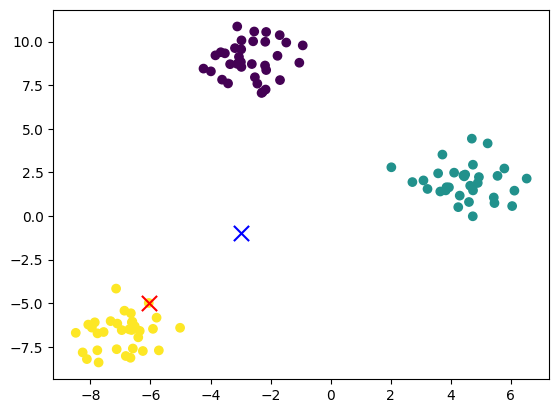

In [9]:
# n = fvecs_read('siftsmall/siftsmall_base.fvecs')
X, y = datasets.make_blobs(n_samples=100, centers=3, n_features=2, random_state=42)
# X, y = datasets.make_moons(n_samples=100, random_state=42)
search = np.array([-3.0, -1.0])

T, _ = hkm(X, k=3, L_max=5, N_min=10)

cl, perf_obj = hkm_search(T, search)
print(cl)
print(X[cl])

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.scatter(search[0], search[1], c='blue', marker='x', s=120)
plt.scatter(X[cl][0], X[cl][1], c='red', marker='x', s=120)
plt.show()

ivec files are the ground truth to test the hkm 
In addition, we provide the groundtruth for each set, in the form of the 
pre-computed k nearest neighbors and their square Euclidean distance.

The groundtruth files contain, for each query, the identifiers (vector number, starting at 0) 
of its k nearest neighbors, ordered by increasing (squared euclidean) distance. 
  • k=100 for the dataset ANN_SIFT10K, ANN_SIFT1M and ANN_GIST1M
Therefore, the first element of each integer vector is the nearest neighbor identifier 
associated with the query. 

The performance measure is recall@R, that is, for varying values of R, 
the average rate of queries for which the 1-nearest neighbor is ranked in the top R positions.
Please use this measure to allow a direct comparison of your system with most 
of the results reported in the literature.



Per testare il sistema devo fare hkm in base poi fare le query in fvecs_query poi confrontare i risultati con il groundtruth, calcolando recall@R

groudtruth sono i 100 vettori della query con i loro 100 vicini più vicini, quindi devo fare hkm sui dati di base e poi confrontare i risultati con il groundtruth, calcolando recall@R

In [138]:
def in_top_k(groundtruth_row, query_result, k):
    # groundtruth_row contains neighbors for one query, sorted by true distance.
    return query_result in groundtruth_row[:k]


def recall_at_r(groundtruth, query_results, r):
    """
    First recall definition with one relevant item per query.

    Here we evaluate if the retrieved id for each query is inside
    the first r true neighbors from the ground-truth row.
    """
    hits = sum(in_top_k(groundtruth[i], query_results[i], r) for i in range(len(query_results)))
    return hits / len(query_results)

# Testing the HKM System

In [ ]:
def read_dataset(size="small"):
    """
    Reads the dataset based on the specified size.
    Parameters:
        size: "small" or "large" to specify which dataset to read.
    Returns:
        A tuple containing the base vectors, query vectors, and ground truth vectors.
    """
    if size == "small":
        return fvecs_read('siftsmall/siftsmall_base.fvecs'), fvecs_read('siftsmall/siftsmall_query.fvecs'), ivecs_read('siftsmall/siftsmall_groundtruth.ivecs')
    elif size == "large":
        # Read large dataset
        return fvecs_read('sift/sift_base.fvecs'), fvecs_read('sift/sift_query.fvecs'), ivecs_read('sift/sift_groundtruth.ivecs')

In [136]:
fvecs_base, fvecs_query, ivecs_groundtruth = read_dataset(size="small")

In [80]:
tree, _ = hkm(fvecs_base, k=5, L_max=5, N_min=10)
queries_result = []
perf_objs = []
for q in fvecs_query:
    
    # start_time = time.perf_counter()
    # idx = hkm_search(tree, q, fvecs_base)
    idx, perf_obj = hkm_search(tree, q)
    # elapsed_ms = (time.perf_counter() - start_time)*1000.0

    queries_result.append(idx)
    perf_objs.append(perf_obj)

In [ ]:
def perf_viz(perf_objs):

    # Build arrays from SearchPerf
    centroid_dist = np.array([p.centroid_distances_time for p in perf_objs])
    centroid_argm = np.array([p.centroid_argmin_time for p in perf_objs])
    leaf_dist     = np.array([p.leaf_distances_time for p in perf_objs])
    leaf_argm     = np.array([p.leaf_argmin_time for p in perf_objs])

    total = centroid_dist + centroid_argm + leaf_dist + leaf_argm
    labels = ["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"]
    parts = [centroid_dist, centroid_argm, leaf_dist, leaf_argm]

    # 1) Total-time distribution
    plt.figure(figsize=(7,4))
    plt.hist(total, bins="fd", edgecolor="black", alpha=0.8)
    plt.xlabel("Total query time (ms)")
    plt.ylabel("Count")
    plt.title("Distribution of total HKM search time")
    plt.grid(alpha=0.2)
    plt.show()

    # 2) Component distributions (boxplot)
    plt.figure(figsize=(8,4))
    plt.boxplot(parts, tick_labels=labels, showfliers=True)
    plt.ylabel("Time (ms)")
    plt.title("Per-query distribution of SearchPerf components")
    plt.grid(axis="y", alpha=0.2)
    plt.xticks(rotation=15)
    plt.show()

    # 3) Median stacked breakdown
    med = np.array([np.median(x) for x in parts])
    plt.figure(figsize=(7,4))
    bottom = 0.0
    for v, name in zip(med, labels):
        plt.bar(["median query"], [v], bottom=bottom, label=name)
        bottom += v
    plt.ylabel("Time (ms)")
    plt.title("Median query time decomposition")
    plt.legend()
    plt.grid(axis="y", alpha=0.2)
    plt.show()

    medians = np.array([np.median(x) for x in parts])
    print(medians)
    pct_median = 100 * medians / medians.sum()
    plt.figure(figsize=(6,6))
    plt.pie(pct_median, labels=labels, autopct="%1.1f%%", startangle=90)
    plt.title("Median percentage contribution by component")
    plt.grid(alpha=0.2)
    plt.show()

    print(f"mean total:   {np.mean(total):.4f} ms")
    print(f"median total: {np.median(total):.4f} ms")
    print(f"p95 total:    {np.percentile(total, 95):.4f} ms")
    print(f"centroid search iterations: {np.sum([p.centroid_iter for p in perf_objs])}")
    print(f"leaf search iterations: {len(perf_objs)}")

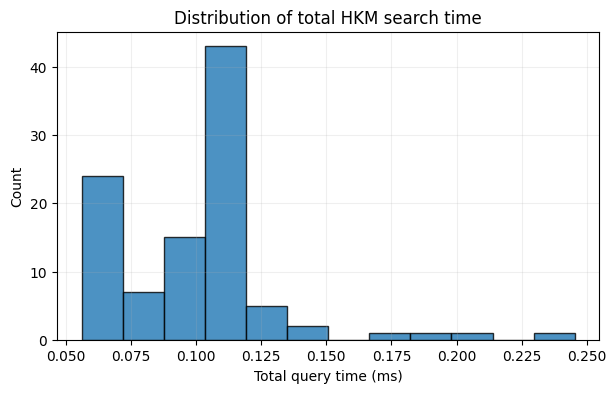

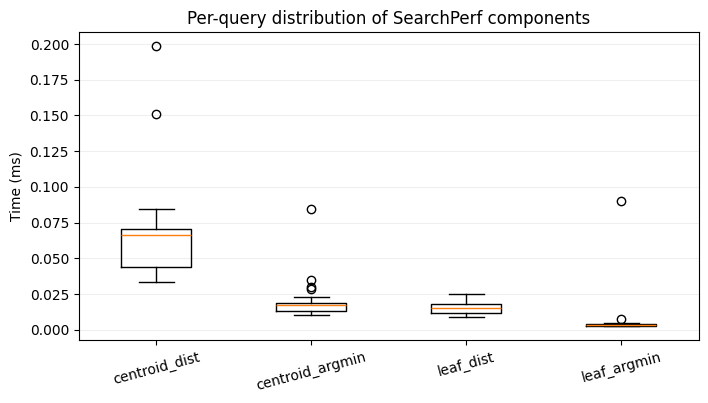

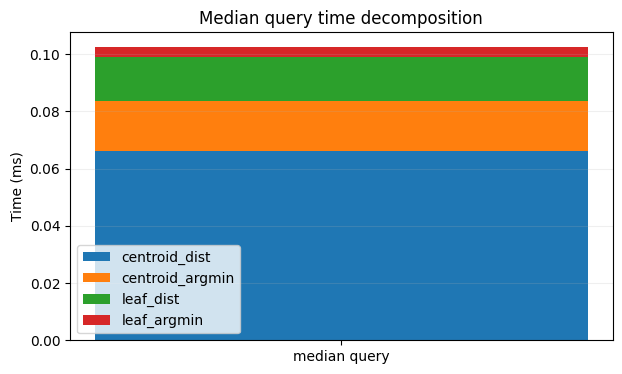

[0.062953 0.017642 0.015366 0.004361]


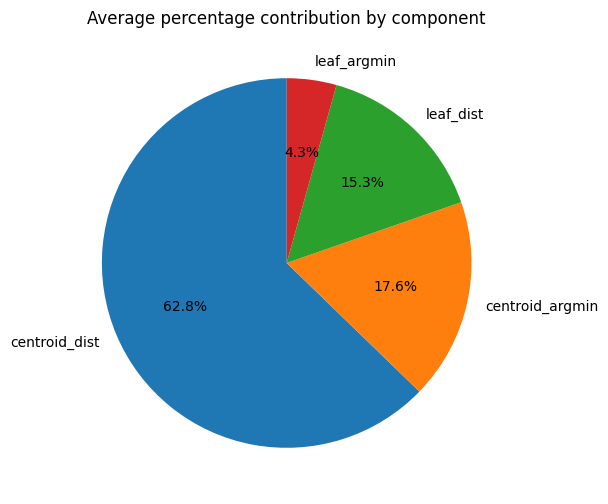

mean total:   0.1003 ms
median total: 0.1042 ms
p95 total:    0.1376 ms
centroid search iterations: 493
leaf search iterations: 100


In [82]:
perf_viz(perf_objs)

In [83]:
for r in [1, 5, 10, 20, 50, 100]:
    #! percentuale di quanti risultati trovati dal mio search sono presenti nei primi r risultati del groundtruth
    print(f"Recall@{r}: {recall_at_r(ivecs_groundtruth, queries_result, r):.4f}")

Recall@1: 0.4000
Recall@5: 0.7000
Recall@10: 0.7500
Recall@20: 0.9000
Recall@50: 0.9600
Recall@100: 1.0000


In [74]:
fvecs_base_l, fvecs_query_l, ivecs_groundtruth_l = read_dataset(size="large")

In [86]:
tree_n, _ = hkm(fvecs_base_l, k=5, L_max=5, N_min=10)
queries_result_l = []
perf_objs_l = []
for q in fvecs_query_l:
    idx, perf_obj = hkm_search(tree_n, q)
    queries_result_l.append(idx)
    perf_objs_l.append(perf_obj)

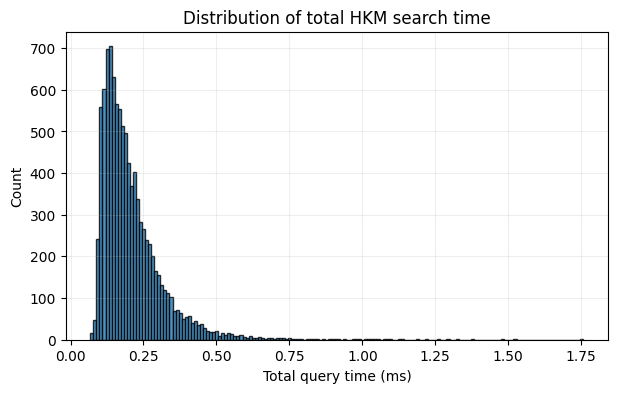

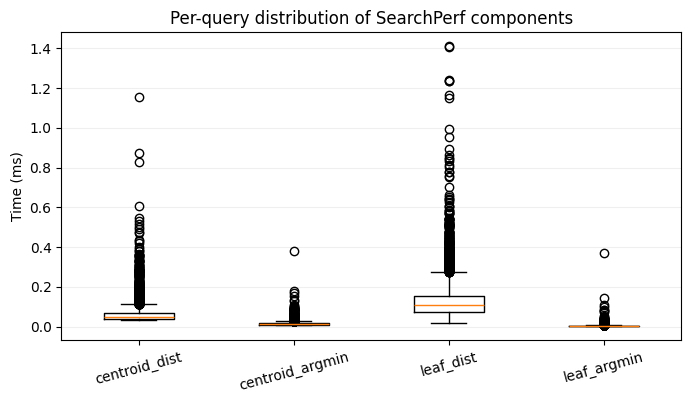

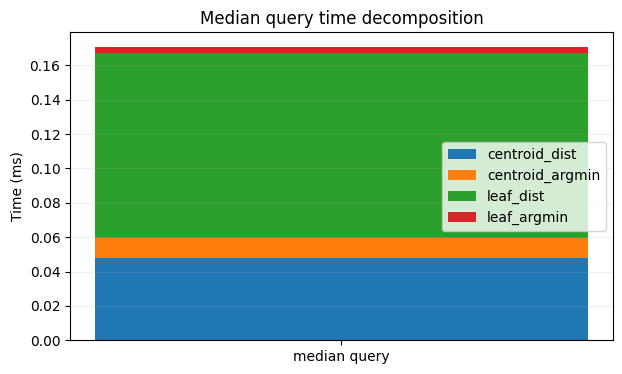

[0.0477 0.0119 0.1075 0.0035]


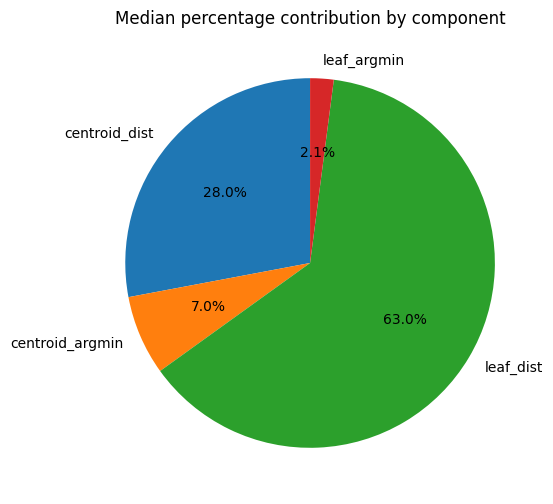

mean total:   0.2085 ms
median total: 0.1800 ms
p95 total:    0.4076 ms
centroid search iterations: 50000
leaf search iterations: 10000


In [143]:
perf_viz(perf_objs_l)

In [87]:
for r in [1, 5, 10, 20, 50, 100]:
    #! percentuale di quanti risultati trovati dal mio search sono presenti nei primi r risultati del groundtruth
    print(f"Recall@{r}: {recall_at_r(ivecs_groundtruth_l, queries_result_l, r):.4f}")

Recall@1: 0.2885
Recall@5: 0.6195
Recall@10: 0.7628
Recall@20: 0.8773
Recall@50: 0.9594
Recall@100: 0.9867


In [9]:
# plotting function for time breakdown vs parameter values (e.g. N_min or k or L_max)
def plot_time_component_breakdown(
    queries_time_per_param,
    param_values,
    param_label,
    title_prefix="Time Component Breakdown",
    figsize=(10, 6),
    alpha=0.8
):
    # Safety: keep aligned lengths in case of partial failures
    n = min(len(queries_time_per_param), len(param_values))
    if n == 0:
        print("No data to plot.")
        return

    x = list(param_values[:n])

    centroid_dist_medians = [
        np.median([p.centroid_distances_time for p in perf_for_this_param])
        for perf_for_this_param in queries_time_per_param[:n]
    ]
    centroid_argm_medians = [
        np.median([p.centroid_argmin_time for p in perf_for_this_param])
        for perf_for_this_param in queries_time_per_param[:n]
    ]
    leaf_dist_medians = [
        np.median([p.leaf_distances_time for p in perf_for_this_param])
        for perf_for_this_param in queries_time_per_param[:n]
    ]
    leaf_argm_medians = [
        np.median([p.leaf_argmin_time for p in perf_for_this_param])
        for perf_for_this_param in queries_time_per_param[:n]
    ]

    print(len(x), len(centroid_dist_medians))  # should match

    plt.figure(figsize=figsize)
    plt.stackplot(
        x,
        centroid_dist_medians,
        centroid_argm_medians,
        leaf_dist_medians,
        leaf_argm_medians,
        labels=["centroid_dist", "centroid_argmin", "leaf_dist", "leaf_argmin"],
        alpha=alpha
    )
    plt.xlabel(param_label)
    plt.ylabel("Time (ms)")
    plt.title(f"{title_prefix} vs {param_label}")
    plt.legend(loc="upper left")
    plt.grid(alpha=0.2)
    plt.show()

In [10]:
# plotting function for recall@r and median time vs parameter values (e.g. N_min or k or L_max)
def plot_hkm_recall_time_tradeoff(
    queries_result_per_param,
    queries_time_per_param,
    param_values,
    groundtruth,
    recall_r=1,
    param_label="parameter",
    title_prefix="HKM",
    figsize=(10, 5),
):
    """
    Plot recall@r and median query time vs a swept HKM parameter.

    Parameters
    ----------
    queries_result_per_param : list[list[int]]
        One list of predicted NN ids per parameter value.
    queries_time_per_param : list[list[SearchPerf]]
        One list of SearchPerf objects per parameter value.
    param_values : sequence
        Values of the swept parameter, aligned with the two lists above.
    groundtruth : numpy array
        Ground-truth neighbors, one row per query.
    recall_r : int
        Cutoff used in recall@r.
    param_label : str
        Label for the x axis and plot title.
    title_prefix : str
        Prefix used in the title.
    figsize : tuple
        Figure size.
    """

    n = min(
        len(queries_result_per_param),
        len(queries_time_per_param),
        len(param_values),
    )

    if n == 0:
        print("No data to plot.")
        return

    x = list(param_values[:n])

    avg_recall_per_param = [
        recall_at_r(groundtruth, queries_result_per_param[i], r=recall_r)
        for i in range(n)
    ]

    median_time_per_param = [
        np.median([p.total_time() for p in queries_time_per_param[i]])
        for i in range(n)
    ]

    print(len(x), len(avg_recall_per_param), len(median_time_per_param))

    fig, ax1 = plt.subplots(figsize=figsize)

    ax1.plot(x, avg_recall_per_param, "o-", color="tab:blue")
    ax1.set_xlabel(param_label)
    ax1.set_ylabel(f"Avg Recall@{recall_r}", color="tab:blue")
    ax1.tick_params(axis="y", labelcolor="tab:blue")
    ax1.grid(alpha=0.25)

    ax2 = ax1.twinx()
    ax2.plot(x, median_time_per_param, "s--", color="tab:red")
    ax2.set_ylabel("Median query time (ms)", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")

    plt.title(f"{title_prefix}: Avg Recall@{recall_r} and Median Time vs {param_label}")
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.scatter(median_time_per_param, avg_recall_per_param, c=x, cmap="viridis")
    plt.xlabel("Median query time (ms)")
    plt.ylabel(f"Avg Recall@{recall_r}")
    plt.title(f"{title_prefix} trade-off per {param_label}")
    cbar = plt.colorbar()
    cbar.set_label(param_label)
    plt.grid(alpha=0.25)
    plt.show()

In [201]:
# fucntion to inspect leaf statistics (size, depth, stop reasons) for a given tree
import pandas as pd
def summarize_parameter_sweep(generated_trees, queries_result_per_param, queries_time_per_param, 
                               param_values, param_name, groundtruth):
    """
    Generalized summary for any parameter sweep (k, N_min, L_max, etc.).
    
    Parameters:
        generated_trees: list of tree objects
        queries_result_per_param: list of query results (one list per parameter value)
        queries_time_per_param: list of performance objects (one list per parameter value)
        param_values: sequence of parameter values tested
        param_name: name of parameter being tested (e.g., "k", "N_min", "L_max")
        groundtruth: ground truth data for recall calculation
    
    Example:
        summarize_parameter_sweep(generated_trees, queries_result_per_k, queries_time_per_k, 
                                  k_range, "k", ivecs_groundtruth)
    """
    import pandas as pd
    
    summary_data = []
    
    for idx, (tree, queries_result, perf_list) in enumerate(zip(generated_trees, queries_result_per_param, queries_time_per_param)):
        param_val = list(param_values)[idx]
        
        # Extract leaf stats
        leaf_sizes = []
        leaf_depths = []
        leaf_stop_reasons = {}
        internal_nodes = 0
        
        def _traverse(node, depth=0):
            nonlocal internal_nodes
            if isinstance(node, LeafNode):
                leaf_sizes.append(len(node.mappings))
                leaf_depths.append(depth)
                reason = node.stop_reason
                leaf_stop_reasons[reason] = leaf_stop_reasons.get(reason, 0) + 1
            else:
                internal_nodes += 1
                for child in node.children:
                    _traverse(child, depth + 1)
        
        _traverse(tree)
        
        # Performance metrics
        total_times = [p.total_time() for p in perf_list]
        
        # Recall metrics
        recall_1 = recall_at_r(groundtruth, queries_result, r=1)
        recall_5 = recall_at_r(groundtruth, queries_result, r=5)
        recall_10 = recall_at_r(groundtruth, queries_result, r=10)
        
        # Stop reason breakdown
        max_depth_pct = 100 * leaf_stop_reasons.get("max_depth", 0) / len(leaf_sizes) if leaf_sizes else 0
        len_d_lt_k_pct = 100 * leaf_stop_reasons.get("len_d_lt_k", 0) / len(leaf_sizes) if leaf_sizes else 0
        len_d_lt_n_min_pct = 100 * leaf_stop_reasons.get("len_d_lt_n_min", 0) / len(leaf_sizes) if leaf_sizes else 0
        
        summary_data.append({
            param_name: param_val,
            "Leaves": len(leaf_sizes),
            "Internal": internal_nodes,
            "Leaf Size": f"{np.mean(leaf_sizes):.1f}" if leaf_sizes else "N/A",
            "Max Depth": max(leaf_depths) if leaf_depths else 0,
            "Recall@1": f"{recall_1:.4f}",
            "Recall@5": f"{recall_5:.4f}",
            "Recall@10": f"{recall_10:.4f}",
            "Median Time (ms)": f"{np.median(total_times):.4f}",
            "Mean Time (ms)": f"{np.mean(total_times):.4f}",
            "P95 Time (ms)": f"{np.percentile(total_times, 95):.4f}",
            "Max_Depth%": f"{max_depth_pct:.1f}%",
            "Lt_K%": f"{len_d_lt_k_pct:.1f}%",
            "Lt_NMin%": f"{len_d_lt_n_min_pct:.1f}%",
        })
    
    df = pd.DataFrame(summary_data)
    
    print("\n" + "=" * 180)
    print(f" {param_name.upper()}-SWEEP SUMMARY")
    print("=" * 180)
    print(df.to_string(index=False))
    print("=" * 180)
    
    return df

test N_min from 10 to 100 steps of 5 on small dataset

In [28]:
queries_result_per_n_min = []
queries_time_per_n_min = []
generated_trees_n = []

N_range = range(5, 2001, 10)

for N in N_range:
    print(f"Testing N_min={N}...")
    try :
        tree, _ = hkm(fvecs_base, k=5, L_max=5, N_min=N)
    except Exception as e:
        print(f"Failed to build tree with N_min={N}: {e}")
        continue
    
    queries_result = []
    queries_time = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj)
    
    generated_trees_n.append(tree)
    queries_time_per_n_min.append(queries_time)
    queries_result_per_n_min.append(queries_result)

Testing N_min=5...
Testing N_min=15...
Testing N_min=25...
Testing N_min=35...
Testing N_min=45...
Testing N_min=55...
Testing N_min=65...
Testing N_min=75...
Testing N_min=85...
Testing N_min=95...
Testing N_min=105...
Testing N_min=115...
Testing N_min=125...
Testing N_min=135...
Testing N_min=145...
Testing N_min=155...
Testing N_min=165...
Testing N_min=175...
Testing N_min=185...
Testing N_min=195...
Testing N_min=205...
Testing N_min=215...
Testing N_min=225...
Testing N_min=235...
Testing N_min=245...
Testing N_min=255...
Testing N_min=265...
Testing N_min=275...
Testing N_min=285...
Testing N_min=295...
Testing N_min=305...
Testing N_min=315...
Testing N_min=325...
Testing N_min=335...
Testing N_min=345...
Testing N_min=355...
Testing N_min=365...
Testing N_min=375...
Testing N_min=385...
Testing N_min=395...
Testing N_min=405...
Testing N_min=415...
Testing N_min=425...
Testing N_min=435...
Testing N_min=445...
Testing N_min=455...
Testing N_min=465...
Testing N_min=475...
Tes

In [29]:
res_n = summarize_parameter_sweep(generated_trees_n, queries_result_per_n_min, queries_time_per_n_min, N_range, "N_min", ivecs_groundtruth)


📊 N_MIN-SWEEP SUMMARY
 N_min  Leaves  Internal Leaf Size  Max Depth Recall@1 Recall@5 Recall@10 Median Time (ms) Mean Time (ms) P95 Time (ms) Max_Depth% Lt_K% Lt_NMin%
     5    2817       704       3.5          5   0.4000   0.7000    0.7500           0.0716         0.0969        0.0910      22.8%  0.0%    77.2%
    15    1673       418       6.0          5   0.4000   0.7100    0.7600           0.0696         0.0701        0.0799       4.1%  0.0%    95.9%
    25    1089       272       9.2          5   0.4200   0.7300    0.7900           0.0920         0.0947        0.1468       0.6%  0.0%    99.4%
    35     805       201      12.4          5   0.4200   0.7400    0.8100           0.0909         0.0947        0.1137       0.2%  0.0%    99.8%
    45     625       156      16.0          5   0.4200   0.7600    0.8300           0.0956         0.1058        0.1529       0.0%  0.0%   100.0%
    55     513       128      19.5          5   0.4300   0.7700    0.8500           0.0644         0.

200 200


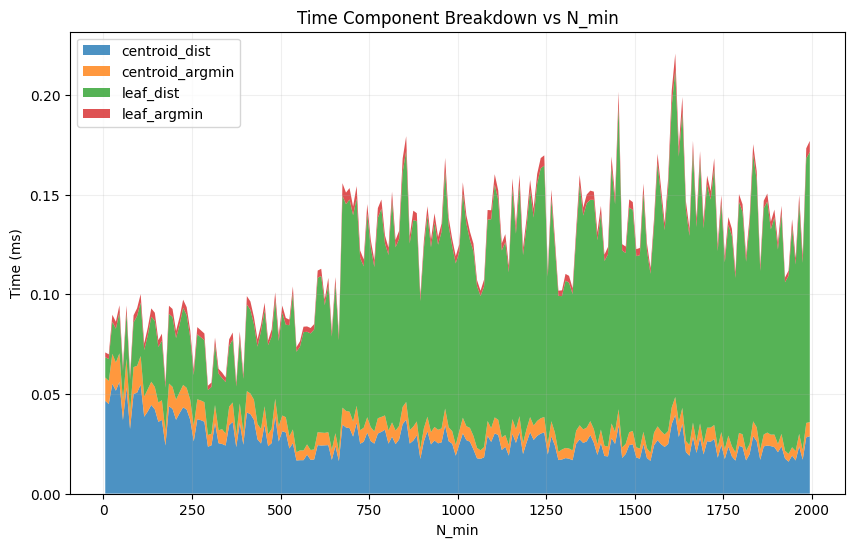

In [30]:
plot_time_component_breakdown(
    queries_time_per_n_min,
    N_range,
    "N_min"
)

200 200 200


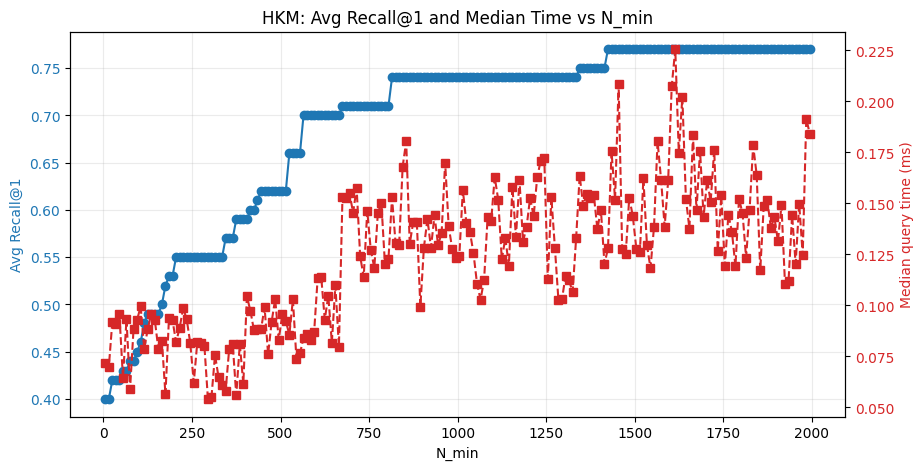

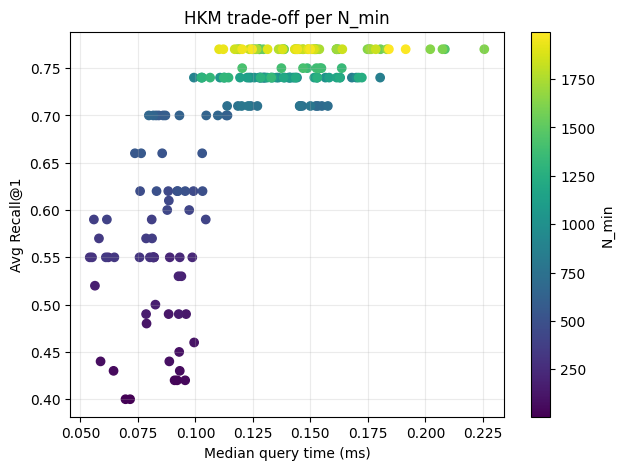

In [31]:
plot_hkm_recall_time_tradeoff(
    queries_result_per_n_min,
    queries_time_per_n_min,
    N_range,
    ivecs_groundtruth,
    recall_r=1,
    param_label="N_min",
    title_prefix="HKM"
)

test k from 2 to 20 steps of 2 on small dataset

In [32]:
queries_time_per_k = []
queries_result_per_k = []
generated_trees_k = []
k_range = range(2, 300, 2)  # test even k values from 2 to 298
for k in k_range:
    print(f"Testing k={k}...")
    try:
        tree, _ = hkm(fvecs_base, k=k, L_max=5, N_min=10)
    except Exception as e:
        print(f"Failed to build tree with k={k}: {e}")
        continue

    queries_result_for_this_k = []
    perf_for_this_k = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result_for_this_k.append(idx)
        perf_for_this_k.append(perf_obj)

    generated_trees_k.append(tree)
    queries_time_per_k.append(perf_for_this_k)
    queries_result_per_k.append(queries_result_for_this_k)

Testing k=2...
Testing k=4...
Testing k=6...
Testing k=8...
Testing k=10...
Testing k=12...
Testing k=14...
Testing k=16...
Testing k=18...
Testing k=20...
Testing k=22...
Testing k=24...
Testing k=26...
Testing k=28...
Testing k=30...
Testing k=32...
Testing k=34...
Testing k=36...
Testing k=38...
Testing k=40...
Testing k=42...
Testing k=44...
Testing k=46...
Testing k=48...
Testing k=50...
Testing k=52...
Testing k=54...
Testing k=56...
Testing k=58...
Testing k=60...
Testing k=62...
Testing k=64...
Testing k=66...
Testing k=68...
Testing k=70...
Testing k=72...
Testing k=74...
Testing k=76...
Testing k=78...
Testing k=80...
Testing k=82...
Testing k=84...
Testing k=86...
Testing k=88...
Testing k=90...
Testing k=92...
Testing k=94...
Testing k=96...
Testing k=98...
Testing k=100...
Testing k=102...
Testing k=104...
Testing k=106...
Testing k=108...
Testing k=110...
Testing k=112...
Testing k=114...
Testing k=116...
Testing k=118...
Testing k=120...
Testing k=122...
Testing k=124...

In [ ]:
res_k = summarize_parameter_sweep(generated_trees_k, queries_result_per_k, queries_time_per_k, k_range, "k", ivecs_groundtruth)


📊 K-SWEEP SUMMARY
  k  Leaves  Internal Leaf Size  Max Depth Recall@1 Recall@5 Recall@10 Median Time (ms) Mean Time (ms) P95 Time (ms) Max_Depth% Lt_K% Lt_NMin%
  2      32        31     312.5          5   0.6700   0.9100    0.9700           0.2029         0.2234        0.3561     100.0%  0.0%     0.0%
  4     991       330      10.1          5   0.4300   0.7000    0.8200           0.1103         0.1167        0.1910      41.0%  0.0%    59.0%
  6    3071       614       3.3          5   0.4400   0.7300    0.8500           0.0624         0.0647        0.0862       1.7%  0.0%    98.3%
  8    3872       553       2.6          5   0.3700   0.5700    0.7400           0.0954         0.1012        0.1552       0.1%  0.0%    99.9%
 10    5005       556       2.0          5   0.3900   0.6500    0.7900           0.0706         0.0732        0.1009       0.0%  0.0%   100.0%
 12    3697       336       2.7          5   0.4000   0.7100    0.8100           0.0655         0.0712        0.0893       

149 149


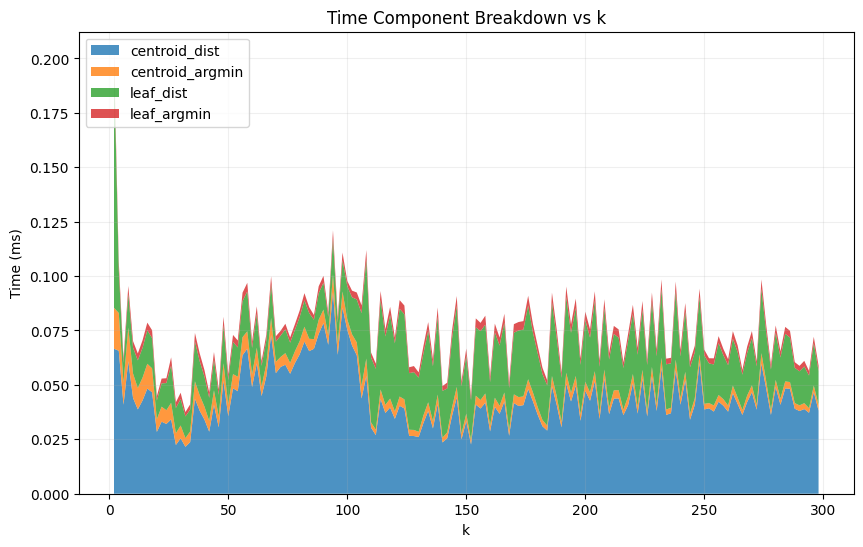

In [40]:
plot_time_component_breakdown(
    queries_time_per_k,
    k_range,
    "k"
)

149 149 149


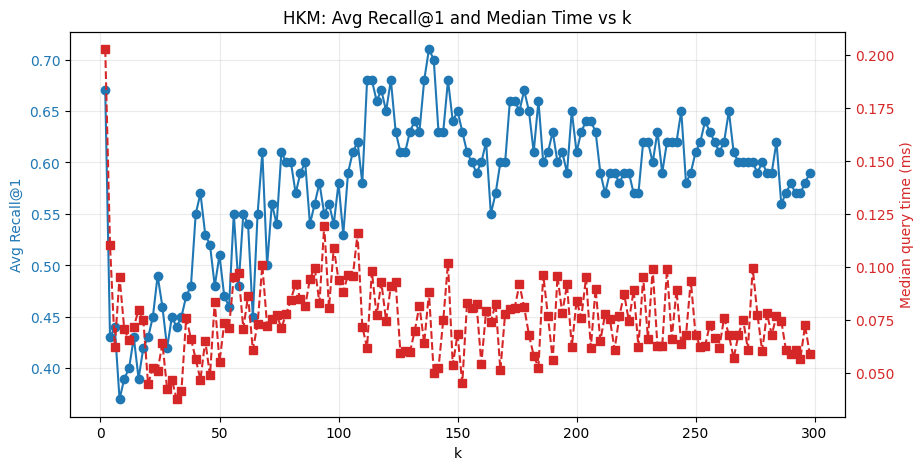

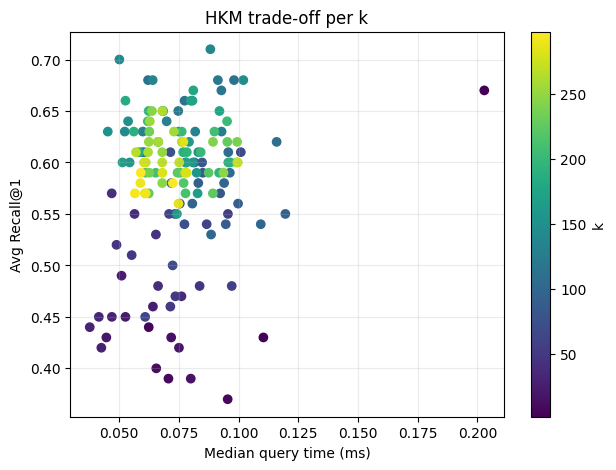

In [35]:
plot_hkm_recall_time_tradeoff(
    queries_result_per_k,
    queries_time_per_k,
    k_range,
    ivecs_groundtruth,
    recall_r=1,
    param_label="k",
    title_prefix="HKM"
)

test L_max from 5 to 20 steps of 5 on small dataset

In [41]:
queries_result_per_l_max = []
queries_time_per_l_max = []
generated_trees_l = []
l_range = range(1, 20)
for L_max in l_range:
    print(f"Testing L_max={L_max}...")
    try :
        tree, _ = hkm(fvecs_base, k=5, L_max=L_max, N_min=10)
    except Exception as e:
        print(f"Failed to build tree with L_max={L_max}: {e}")
        continue
    
    queries_result = []
    queries_time = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj)
    
    generated_trees_l.append(tree)
    queries_time_per_l_max.append(queries_time)
    queries_result_per_l_max.append(queries_result)

Testing L_max=1...
Testing L_max=2...
Testing L_max=3...
Testing L_max=4...
Testing L_max=5...
Testing L_max=6...
Testing L_max=7...
Testing L_max=8...
Testing L_max=9...
Testing L_max=10...
Testing L_max=11...
Testing L_max=12...
Testing L_max=13...
Testing L_max=14...
Testing L_max=15...
Testing L_max=16...
Testing L_max=17...
Testing L_max=18...
Testing L_max=19...


In [42]:
res_l = summarize_parameter_sweep(generated_trees_l, queries_result_per_l_max, queries_time_per_l_max, l_range, "L_max", ivecs_groundtruth)


📊 L_MAX-SWEEP SUMMARY
 L_max  Leaves  Internal Leaf Size  Max Depth Recall@1 Recall@5 Recall@10 Median Time (ms) Mean Time (ms) P95 Time (ms) Max_Depth% Lt_K% Lt_NMin%
     1       5         1    2000.0          1   0.9600   1.0000    1.0000           1.0975         0.9725        1.2525     100.0%  0.0%     0.0%
     2      25         6     400.0          2   0.7400   0.9400    0.9800           0.0779         0.0859        0.1472     100.0%  0.0%     0.0%
     3     125        31      80.0          3   0.5300   0.8400    0.8900           0.0602         0.0632        0.0974     100.0%  0.0%     0.0%
     4     625       156      16.0          4   0.4400   0.7800    0.8500           0.0464         0.0683        0.0995      62.7%  0.0%    37.3%
     5    2193       548       4.6          5   0.4000   0.7000    0.7500           0.0694         0.0841        0.1094       8.1%  0.0%    91.9%
     6    2901       725       3.4          6   0.3900   0.6900    0.7400           0.1019         0.

19 19


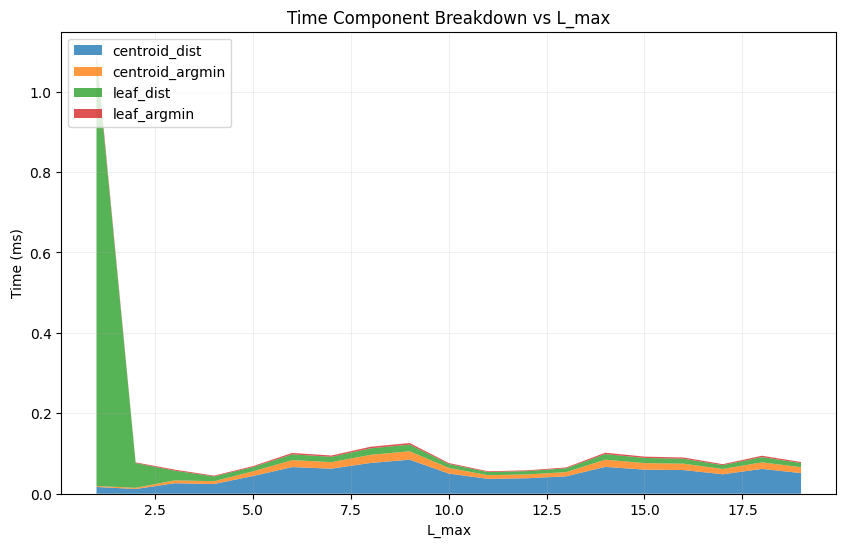

In [43]:
plot_time_component_breakdown(
    queries_time_per_l_max,
    l_range,
    "L_max"
)

19 19 19


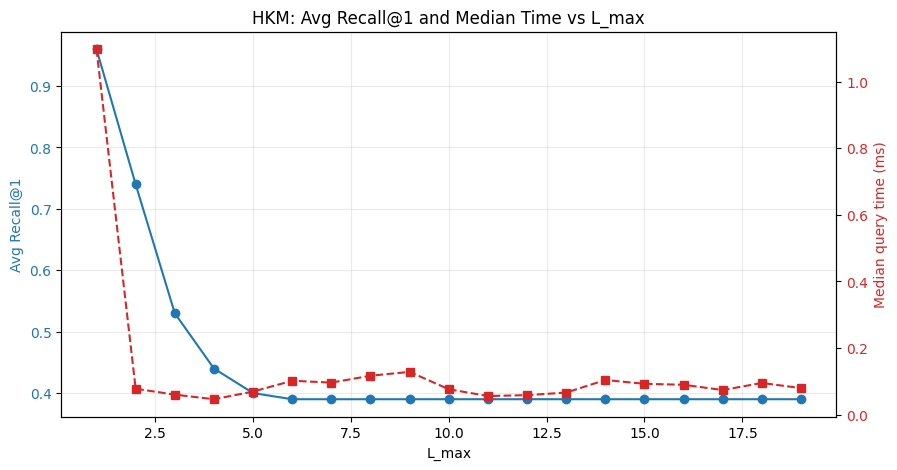

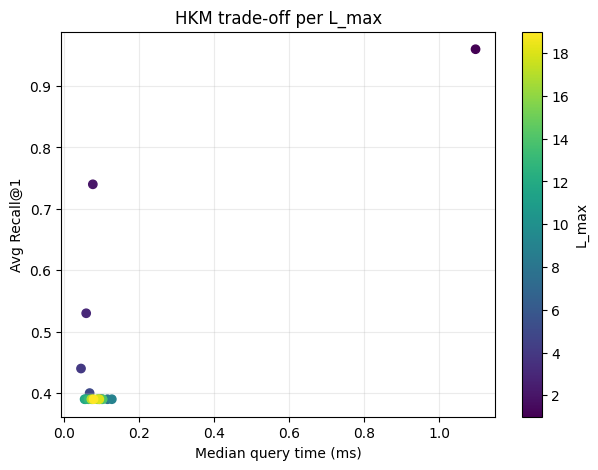

In [44]:
plot_hkm_recall_time_tradeoff(
    queries_result_per_l_max,
    queries_time_per_l_max,
    l_range,
    ivecs_groundtruth,
    recall_r=1,
    param_label="L_max",
    title_prefix="HKM"
)

with the learn dataset ? 

Possible values from single observations : 
+ N_min = 500 , 1500
+ k = 75 175
+ L_max = 2 5 

### HKM test for best parameters

Parameters to test: 
+ k: branching factor -> k >= 2
+ L_max: maximum number of layers in the hierarchy -> L_max >= 1
+ N_min: minimum number of points in a leaf node -> N_min >= 1 , <= number of points in the dataset 

trova bound per dataset da 1M

plan :
+ faccio grid search per capire quali sono i range più promettenti per i parametri
+ faccio optuna per trovare i parametri ottimali, con pruning basato su recall@1 e recall@5 

In [154]:
param_grid = {
    "k" : range(2, 300, 20),
    "L_max": range(1, 50, 10),
    "N_min": range(5, 2001, 200),
}

results_grid_search = {}
for k in param_grid["k"]:
    for L_max in param_grid["L_max"]:
        for N_min in param_grid["N_min"]:
            print(f"Testing k={k}, L_max={L_max}, N_min={N_min}...")
            try:
                tree, _ = hkm(fvecs_base, k=k, L_max=L_max, N_min=N_min)
            except Exception as e:
                print(f"Failed to build tree with k={k}, L_max={L_max}, N_min={N_min}: {e}")
                continue

            queries_result_for_this_combo = []
            perf_for_this_combo = []
            for q in fvecs_query:
                idx, perf_obj = hkm_search(tree, q)
                queries_result_for_this_combo.append(idx)
                perf_for_this_combo.append(perf_obj)

            # Store results in a structured way, e.g. a dictionary keyed by parameter tuples
            results_grid_search[(k, L_max, N_min)] = (queries_result_for_this_combo, perf_for_this_combo)

Testing k=2, L_max=1, N_min=5...
Testing k=2, L_max=1, N_min=205...
Testing k=2, L_max=1, N_min=405...
Testing k=2, L_max=1, N_min=605...
Testing k=2, L_max=1, N_min=805...
Testing k=2, L_max=1, N_min=1005...
Testing k=2, L_max=1, N_min=1205...
Testing k=2, L_max=1, N_min=1405...
Testing k=2, L_max=1, N_min=1605...
Testing k=2, L_max=1, N_min=1805...
Testing k=2, L_max=11, N_min=5...
Testing k=2, L_max=11, N_min=205...
Testing k=2, L_max=11, N_min=405...
Testing k=2, L_max=11, N_min=605...
Testing k=2, L_max=11, N_min=805...
Testing k=2, L_max=11, N_min=1005...
Testing k=2, L_max=11, N_min=1205...
Testing k=2, L_max=11, N_min=1405...
Testing k=2, L_max=11, N_min=1605...
Testing k=2, L_max=11, N_min=1805...
Testing k=2, L_max=21, N_min=5...
Testing k=2, L_max=21, N_min=205...
Testing k=2, L_max=21, N_min=405...
Testing k=2, L_max=21, N_min=605...
Testing k=2, L_max=21, N_min=805...
Testing k=2, L_max=21, N_min=1005...
Testing k=2, L_max=21, N_min=1205...
Testing k=2, L_max=21, N_min=140

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [157]:
def plot_colored_by_each_param(df, recall_r=1, figsize=(18, 5), cmap="viridis", annotate_top=0):
    # Auto-expand params tuple if needed
    if "k" not in df.columns:
        if "params" in df.columns:
            df = df.copy()
            df[["k", "L_max", "N_min"]] = pd.DataFrame(df["params"].tolist(), index=df.index)
        else:
            raise ValueError("Missing columns: expected ['k','L_max','N_min'] or 'params'.")

    params = ["k", "L_max", "N_min"]
    fig, axes = plt.subplots(1, 3, figsize=figsize)

    for ax, p in zip(axes, params):
        sc = ax.scatter(
            df["median_time"], df["recall"],
            c=df[p], cmap=cmap, s=65, alpha=0.85, edgecolors="none"
        )
        ax.set_xlabel("Median query time (ms)")
        ax.set_ylabel(f"Recall@{recall_r}")
        ax.set_title(f"Color by {p}")
        ax.grid(alpha=0.25)
        cbar = plt.colorbar(sc, ax=ax)
        cbar.set_label(p)

        if annotate_top > 0:
            top = df.sort_values(["recall", "median_time"], ascending=[False, True]).head(annotate_top)
            for _, row in top.iterrows():
                ax.annotate(
                    f"(k={int(row['k'])},L={int(row['L_max'])},N={int(row['N_min'])})",
                    (row["median_time"], row["recall"]),
                    textcoords="offset points", xytext=(5, 5), fontsize=7
                )

    plt.tight_layout()
    plt.show()

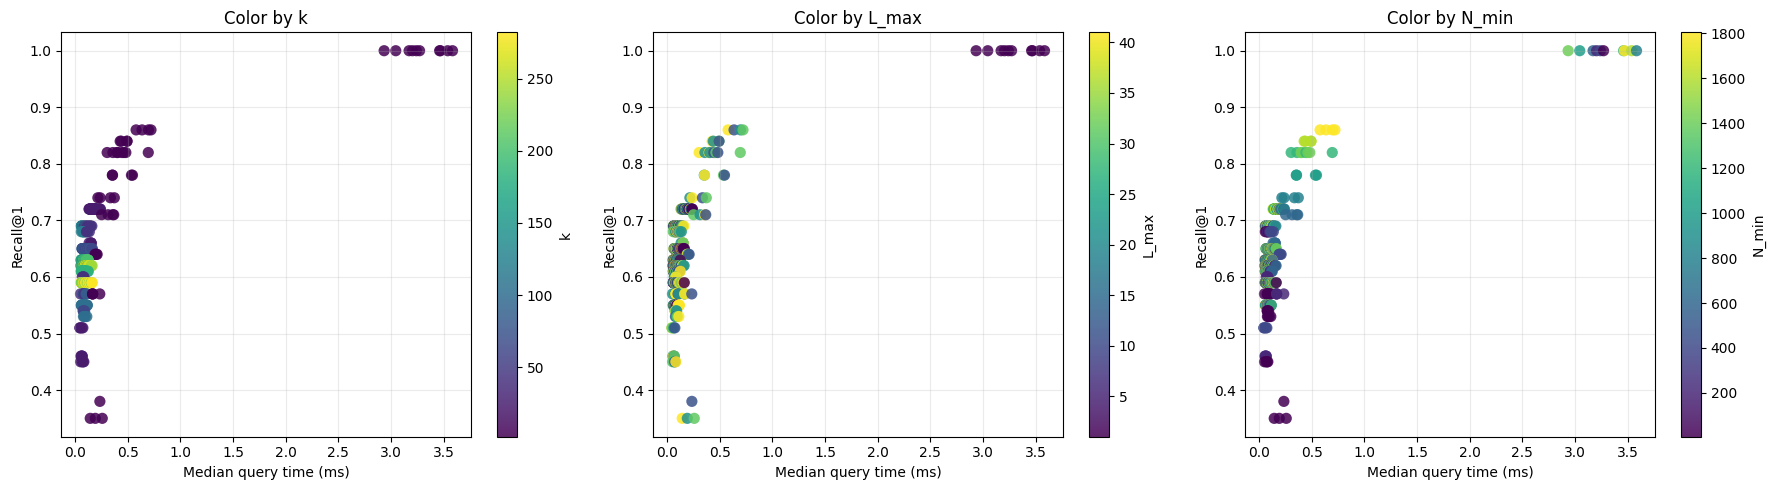

In [160]:
plot_colored_by_each_param(df, recall_r=1, annotate_top=0)

In [ ]:
def plot_recall_vs_time_zoomed(results, groundtruth, recall_r=1, max_recall=0.75, 
                               annotate_top=5, figsize=(9,6), time_unit='ms'):
    """
    Plot Recall@r vs median query time, zoomed to max_recall.
    Same as plot_recall_vs_time but filters results to recall <= max_recall for focused view.
    """
    
    def _recall_at_r(gt, preds, r):
        hits = sum(1 for i, p in enumerate(preds) if p in gt[i][:r])
        return hits / len(preds)

    if isinstance(results, dict):
        items = results.items()
    else:
        items = results

    rows = []
    for params, (preds, perfs) in items:
        recall = _recall_at_r(groundtruth, preds, recall_r)
        
        times = []
        for p in perfs:
            if hasattr(p, "total_time"):
                try:
                    times.append(float(p.total_time()))
                except Exception:
                    times.append(np.nan)
            elif isinstance(p, (int, float, np.floating, np.integer)):
                times.append(float(p))
            else:
                try:
                    times.append(float(p))
                except Exception:
                    times.append(np.nan)
        times = np.array(times, dtype=float)
        median_t = float(np.nanmedian(times)) if len(times) else np.nan
        mean_t = float(np.nanmean(times)) if len(times) else np.nan
        p95_t = float(np.nanpercentile(times, 95)) if len(times) else np.nan

        rows.append({
            "params": params,
            "recall": recall,
            "median_time": median_t,
            "mean_time": mean_t,
            "p95_time": p95_t,
            "n_queries": len(times),
        })

    df = pd.DataFrame(rows)
    df_zoomed = df[df["recall"] <= max_recall].sort_values(
        ["recall", "median_time"], ascending=[False, True]
    ).reset_index(drop=True)

    if len(df_zoomed) == 0:
        print(f"No configs with recall <= {max_recall}")
        return df_zoomed

    fig, ax = plt.subplots(figsize=figsize)
    sc = ax.scatter(df_zoomed["median_time"], df_zoomed["recall"], 
                    c=np.arange(len(df_zoomed)), cmap="viridis", s=80, alpha=0.7)
    ax.set_xlabel(f"Median query time ({time_unit})", fontsize=11)
    ax.set_ylabel(f"Recall@{recall_r}", fontsize=11)
    ax.set_title(f"Recall@{recall_r} vs Median Query Time (zoomed: recall ≤ {max_recall})", fontsize=12)
    ax.grid(alpha=0.2)
    cbar = plt.colorbar(sc, ax=ax, label="sorted index")

    if annotate_top and len(df_zoomed):
        top = df_zoomed.head(annotate_top)
        for _, row in top.iterrows():
            ax.annotate(str(row["params"]), (row["median_time"], row["recall"]),
                        textcoords="offset points", xytext=(5,5), fontsize=7, alpha=0.8)

    plt.tight_layout()
    plt.show()
    
    print(f"\n📊 ZOOMED STATS (recall ≤ {max_recall}):")
    print(f"  Configs shown: {len(df_zoomed)} / {len(df)}")
    print(f"  Recall range:  {df_zoomed['recall'].min():.4f} → {df_zoomed['recall'].max():.4f}")
    print(f"  Time range:    {df_zoomed['median_time'].min():.4f} → {df_zoomed['median_time'].max():.4f} ms")
    
    return df_zoomed

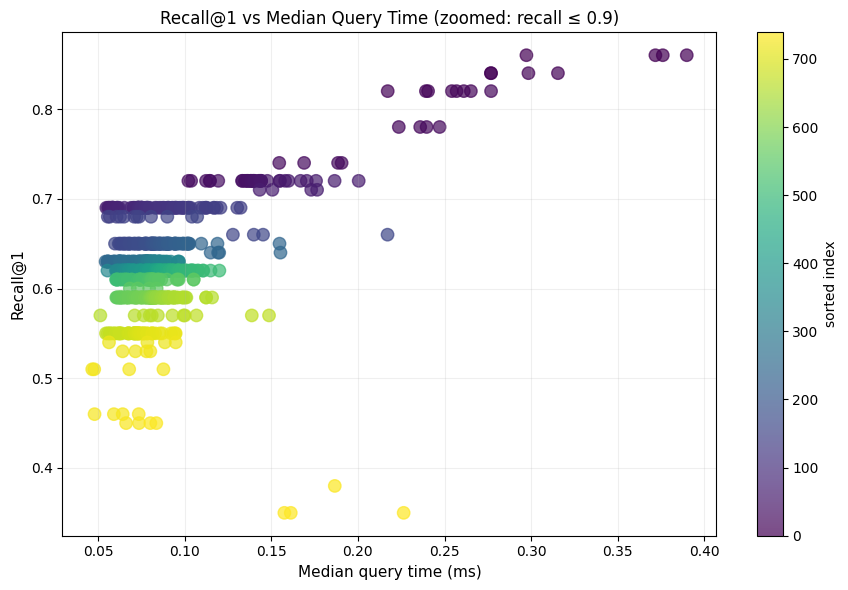


📊 ZOOMED STATS (recall ≤ 0.9):
  Configs shown: 740 / 750
  Recall range:  0.3500 → 0.8600
  Time range:    0.0466 → 0.3898 ms


In [95]:
df_zoomed = plot_recall_vs_time_zoomed(results, ivecs_groundtruth, recall_r=1, max_recall=0.9, annotate_top=0)

In [ ]:
def plot_pareto_frontier_multiobjective(df_or_results, groundtruth=None, recall_r=1, max_recall=None,
                                        figsize=(7, 5), time_unit='ms'):
    """
    Plot true Pareto frontier for multi-objective optimization:
    - Objective 1: MAXIMIZE recall@r
    - Objective 2: MINIMIZE query time
    """
    if isinstance(df_or_results, dict):
        if groundtruth is None:
            raise ValueError("groundtruth required when passing results dict")

        def _recall_at_r(gt, preds, r):
            hits = sum(1 for i, p in enumerate(preds) if p in gt[i][:r])
            return hits / len(preds)

        rows = []
        for params, (preds, perfs) in df_or_results.items():
            recall = _recall_at_r(groundtruth, preds, recall_r)
            times = []
            for p in perfs:
                if hasattr(p, "total_time"):
                    try:
                        times.append(float(p.total_time()))
                    except Exception:
                        times.append(np.nan)
                else:
                    try:
                        times.append(float(p))
                    except Exception:
                        times.append(np.nan)
            times = np.array(times, dtype=float)
            median_t = float(np.nanmedian(times)) if len(times) else np.nan
            rows.append({"params": params, "recall": recall, "median_time": median_t})
        df = pd.DataFrame(rows)
    else:
        df = df_or_results.copy()

    if max_recall is not None:
        df = df[df["recall"] <= max_recall]

    if len(df) == 0:
        print("No data to plot")
        return pd.DataFrame()

    pareto_mask = []
    for i, row_i in df.iterrows():
        is_dominated = False
        for j, row_j in df.iterrows():
            if i == j:
                continue
            if (row_j["recall"] >= row_i["recall"] and row_j["median_time"] <= row_i["median_time"]) and \
               (row_j["recall"] > row_i["recall"] or row_j["median_time"] < row_i["median_time"]):
                is_dominated = True
                break
        pareto_mask.append(not is_dominated)

    df_pareto = df[pareto_mask].sort_values("recall").reset_index(drop=True)

    fig, ax1 = plt.subplots(figsize=figsize)

    ax1.scatter(df["median_time"], df["recall"], c='lightblue', s=60, alpha=0.35,
                label=f'All configs ({len(df)})', edgecolors='gray', linewidth=0.5)
    ax1.scatter(df_pareto["median_time"], df_pareto["recall"], c='red', s=90,
                alpha=0.95, label=f'Pareto frontier ({len(df_pareto)})',
                edgecolors='darkred', linewidth=1.5, marker='o')
    ax1.plot(df_pareto["median_time"], df_pareto["recall"], 'r--', alpha=0.7, linewidth=2, label='Frontier')

    ax1.set_xlabel(f"Median query time ({time_unit})", fontsize=11)
    ax1.set_ylabel(f"Recall@{recall_r}", fontsize=11)
    ax1.set_title("HKM Pareto Frontier\n(Maximize Recall, Minimize Time)", fontsize=12)
    ax1.legend(loc='best', fontsize=10)
    ax1.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    print(f"\nPARETO FRONTIER")
    print(f"Total configs: {len(df)}")
    print(f"Pareto optimal: {len(df_pareto)}")

    print("\nPARETO CONFIGS")
    for _, row in df_pareto.iterrows():
        params = row["params"]
        if isinstance(params, tuple) and len(params) == 3:
            k, L_max, N_min = params
            print(
                f"k={k}, L_max={L_max}, N_min={N_min} | "
                f"recall={row['recall']:.4f} | "
                f"median_time={row['median_time']:.4f} ms"
            )
        else:
            print(
                f"params={params} | "
                f"recall={row['recall']:.4f} | "
                f"median_time={row['median_time']:.4f} ms"
            )

    return df_pareto

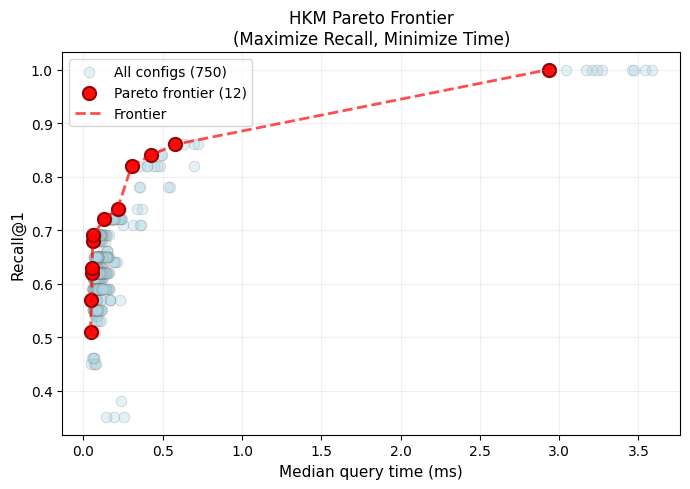


PARETO FRONTIER
Total configs: 750
Pareto optimal: 12

PARETO CONFIGS
k=22, L_max=41, N_min=405 | recall=0.5100 | median_time=0.0452 ms
k=42, L_max=21, N_min=5 | recall=0.5700 | median_time=0.0504 ms
k=162, L_max=21, N_min=405 | recall=0.6200 | median_time=0.0549 ms
k=142, L_max=21, N_min=405 | recall=0.6300 | median_time=0.0555 ms
k=122, L_max=31, N_min=5 | recall=0.6800 | median_time=0.0584 ms
k=122, L_max=21, N_min=805 | recall=0.6900 | median_time=0.0590 ms
k=22, L_max=31, N_min=1805 | recall=0.7200 | median_time=0.1317 ms
k=2, L_max=21, N_min=805 | recall=0.7400 | median_time=0.2157 ms
k=2, L_max=41, N_min=1205 | recall=0.8200 | median_time=0.3039 ms
k=2, L_max=41, N_min=1605 | recall=0.8400 | median_time=0.4276 ms
k=2, L_max=41, N_min=1805 | recall=0.8600 | median_time=0.5789 ms
k=2, L_max=1, N_min=1405 | recall=1.0000 | median_time=2.9350 ms


In [198]:
# From zoomed DataFrame or directly from results dict:
pareto_frontier = plot_pareto_frontier_multiobjective(results_grid_search, groundtruth=ivecs_groundtruth, 
                                                       recall_r=1, max_recall=1)

In [106]:
from optuna.storages import RDBStorage
import optuna
from optuna.pruners import ThresholdPruner
from optuna import TrialPruned
from optuna.trial import TrialState

storage = RDBStorage("sqlite:///db.sqlite3")

In [ ]:
# for the small dataset

def objective(trial):
    k = trial.suggest_int('k', 2, 175)
    L_max = trial.suggest_int('L_max', 2, 10) # il problema è che le soluzioni preferiscono sempre L_max più basso 
    N_min = trial.suggest_int('N_min', 2, 1500)

    tree, _ = hkm(fvecs_base, k=k, L_max=L_max, N_min=N_min)

    queries_result = []
    queries_time = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj.total_time())

    # Compute average recall@1 across all queries
    r = 1
    avg_recall = recall_at_r(ivecs_groundtruth, queries_result, r=r) 
    median_time = np.median(queries_time)

    return avg_recall, median_time

study = optuna.create_study(directions=['maximize', 'minimize'], storage=storage, study_name="hkm_optimization_10k_recall@1", load_if_exists=True)
study.set_metric_names(['recall@1', 'median_time_ms'])
study.optimize(objective, n_trials=1000)

study.best_trials 

NameError: name 'optuna' is not defined

Fissa una recall che vogliamo raggiungere e poi trova i parametri che ci permettono di raggiungerla con il tempo più basso possibile , vorrei recall@1 >= 0.9 e recall@5 >= 0.95 

In [ ]:
RECALL1_TARGET = 0.6
RECALL5_TARGET = 0.75
PENALTY = 1e9


TIME_BUDGET_MS = 0.5
RECALL_BOTTOM = 0.7

def objective(trial):
    k = trial.suggest_int('k', 2, 150, log=True)
    L_max = trial.suggest_int('L_max', 2, 10, log=True) # il problema è che le soluzioni preferiscono sempre L_max più basso 
    N_min = trial.suggest_int('N_min', k, 1500, log=True)

    tree, stats = hkm(fvecs_base, k=k, L_max=L_max, N_min=N_min)

    for key, value in stats.items():
        trial.set_user_attr(key, value)

    trial.set_user_attr("theoretical_avg_leaf_nodes", len(fvecs_base) / k**(L_max)) #! formula approssimata per il numero medio di nodi visitati in una ricerca, da prendere con le pinze ma può essere interessante da monitorare
    trial.set_user_attr("data_to_fill_all_leafs", N_min * (k**(L_max))) 

    queries_result = []
    queries_time = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        queries_time.append(perf_obj.total_time())

    # Compute average recall@1 across all queries
    avg_recall_1 = recall_at_r(ivecs_groundtruth, queries_result, r=1) 
    avg_recall_5 = recall_at_r(ivecs_groundtruth, queries_result, r=5)
    trial.set_user_attr("avg_recall_1", avg_recall_1)
    trial.set_user_attr("avg_recall_5", avg_recall_5)
    median_time = np.median(queries_time)

    # violation = max(RECALL1_TARGET - avg_recall_1, RECALL5_TARGET - avg_recall_5)
    
    # trial.report(violation, step=0)
    # if trial.should_prune():
    #     raise TrialPruned()
    # if avg_recall_1 < RECALL1_TARGET or avg_recall_5 < RECALL5_TARGET:
    #     return PENALTY

    if avg_recall_1 < RECALL_BOTTOM:
        raise TrialPruned()
    
    if median_time > TIME_BUDGET_MS:  # e.g., 10 ms max
        raise TrialPruned()

    return median_time

study = optuna.create_study(directions=['minimize'],pruner=ThresholdPruner(upper=0.0),storage=storage, study_name="hkm_optimization_10k_target_extreme_pruning_log_", load_if_exists=True)
study.set_metric_names(['median_time_ms'])
study.optimize(objective, n_trials=1000)

study.best_trials 

[I 2026-04-28 22:11:22,271] A new study created in RDB with name: hkm_optimization_10k_target_extreme_pruning_log_
C:\Users\Filippo Gumiero\AppData\Local\Temp\ipykernel_17736\1756660364.py:53: ExperimentalWarning:

optuna.study.study.Study.set_metric_names is experimental (supported from v3.2.0). The interface can change in the future.

[I 2026-04-28 22:11:24,653] Trial 0 pruned. 
[I 2026-04-28 22:11:25,339] Trial 1 pruned. 
[I 2026-04-28 22:11:27,870] Trial 2 pruned. 
[I 2026-04-28 22:11:30,219] Trial 3 pruned. 
[I 2026-04-28 22:11:31,514] Trial 4 pruned. 
[I 2026-04-28 22:11:32,072] Trial 5 finished with value: {'median_time_ms': 0.22980000721872784} and parameters: {'k': 14, 'L_max': 5, 'N_min': 1074}. Best is trial 5 with value: 0.22980000721872784.
[I 2026-04-28 22:11:33,018] Trial 6 pruned. 
[I 2026-04-28 22:11:34,664] Trial 7 pruned. 
[I 2026-04-28 22:11:35,622] Trial 8 pruned. 
[I 2026-04-28 22:11:38,865] Trial 9 pruned. 
[I 2026-04-28 22:11:45,382] Trial 10 pruned. 
[I 2026-04

KeyboardInterrupt: 

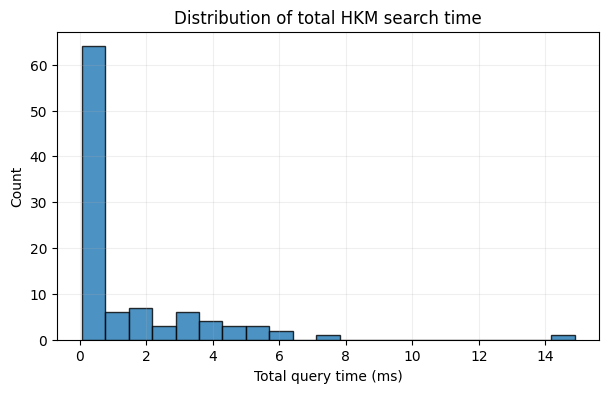

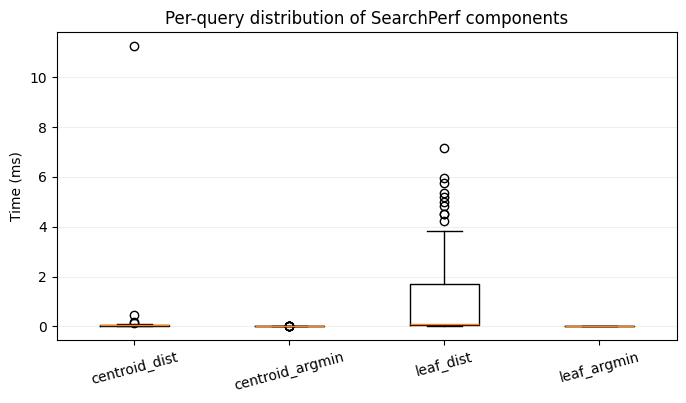

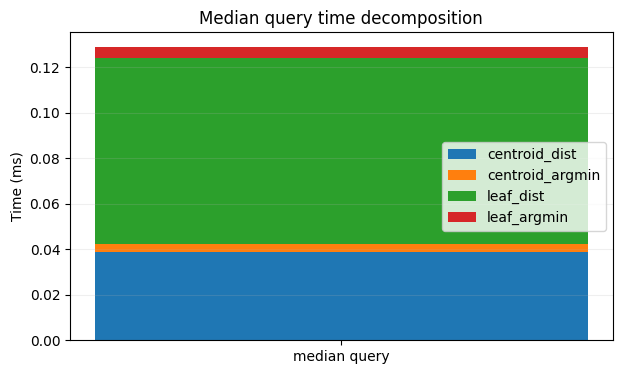

[0.03884999 0.0035     0.08165    0.00499999]


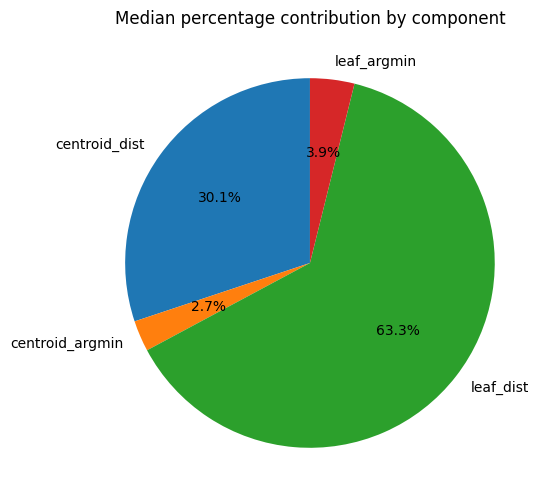

mean total:   1.3484 ms
median total: 0.1599 ms
p95 total:    5.3065 ms
centroid search iterations: 100
leaf search iterations: 100
Recall@1: 0.7000
Recall@5: 0.9500

Testing best config on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...
Querying with k=76, L_max=14, N_min=743 on larger dataset...

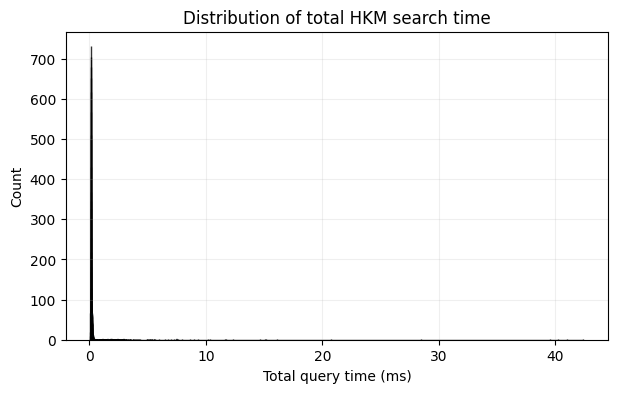

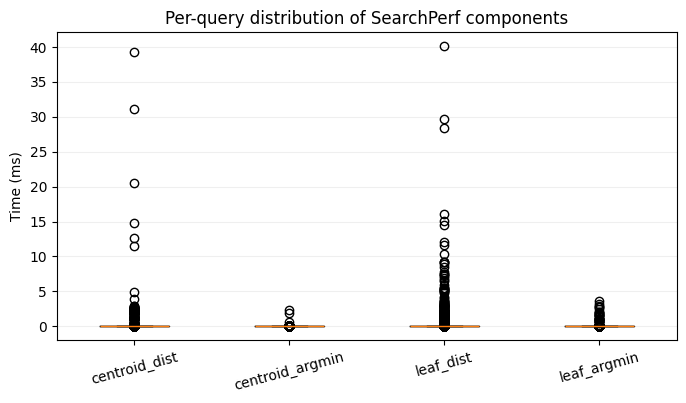

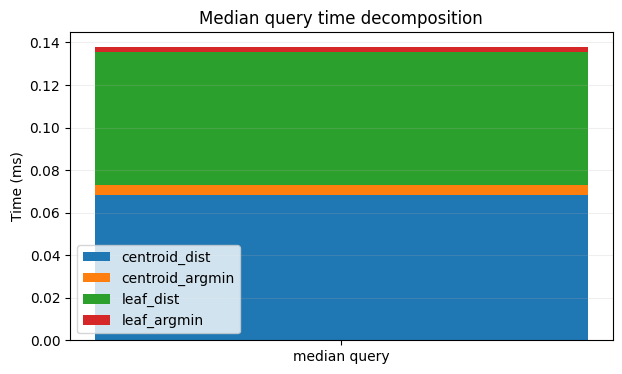

[0.0682     0.00470001 0.0625     0.0025    ]


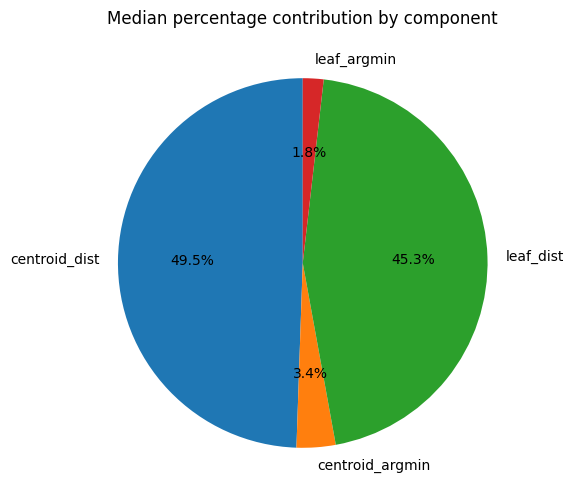

mean total:   0.2425 ms
median total: 0.1390 ms
p95 total:    0.2749 ms
centroid search iterations: 20015
leaf search iterations: 10000
Recall@1: 0.3066
Recall@5: 0.6377


In [161]:
# best trail k=76, L_max=14, N_min = 743
tree, stats = hkm(fvecs_base, k=76, L_max=14, N_min=743)
queries_result = []
queries_time = []
for q in fvecs_query:
    idx, perf_obj = hkm_search(tree, q)
    queries_result.append(idx)
    queries_time.append(perf_obj)

perf_viz(queries_time)
print(f"Recall@1: {recall_at_r(ivecs_groundtruth, queries_result, r=1):.4f}")
print(f"Recall@5: {recall_at_r(ivecs_groundtruth, queries_result, r=5):.4f}")

tree, stats = hkm(fvecs_base_l, k=76, L_max=14, N_min=743)
print("\nTesting best config on larger dataset...")
queries_result = []
queries_time = []
for q in fvecs_query_l:
    print(f"Querying with k=76, L_max=14, N_min=743 on larger dataset...")
    idx, perf_obj = hkm_search(tree, q)
    queries_result.append(idx)
    queries_time.append(perf_obj)

perf_viz(queries_time)
print(f"Recall@1: {recall_at_r(ivecs_groundtruth_l, queries_result, r=1):.4f}")
print(f"Recall@5: {recall_at_r(ivecs_groundtruth_l, queries_result, r=5):.4f}")

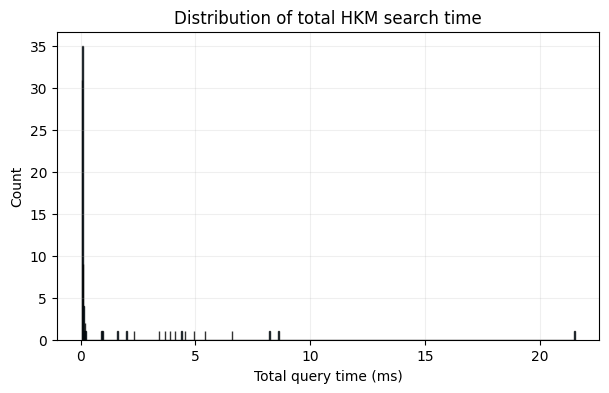

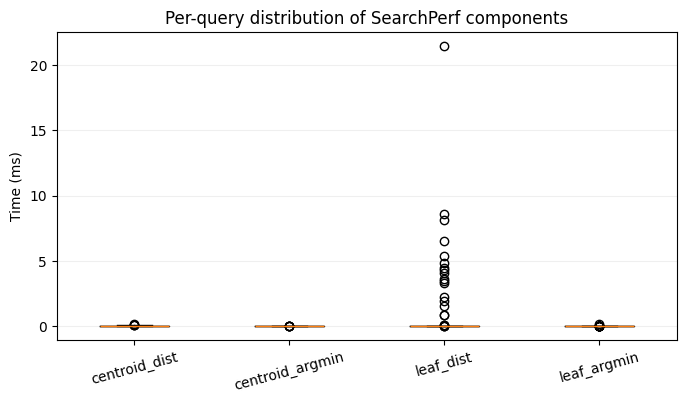

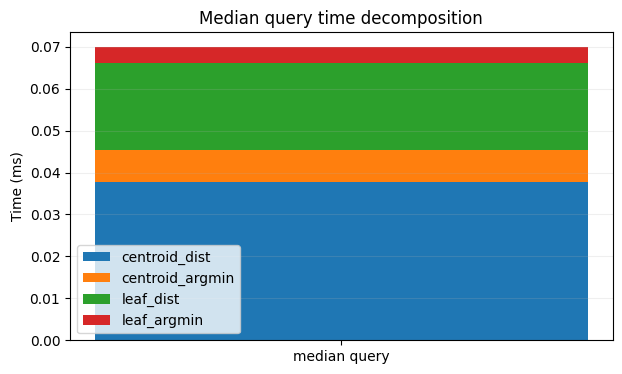

[0.03775    0.00760001 0.0207     0.0039    ]


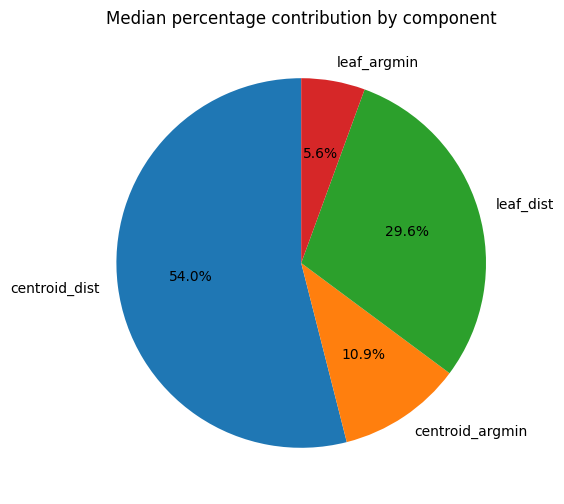

mean total:   0.9375 ms
median total: 0.0838 ms
p95 total:    4.9529 ms
centroid search iterations: 222
leaf search iterations: 100
Recall@1: 0.5500
Recall@5: 0.8300


In [172]:
tree, stats = hkm(fvecs_base, k=27, L_max=6, N_min=5)
queries_result = []
queries_time = []
for q in fvecs_query:
    idx, perf_obj = hkm_search(tree, q)
    queries_result.append(idx)
    queries_time.append(perf_obj)

perf_viz(queries_time)
print(f"Recall@1: {recall_at_r(ivecs_groundtruth, queries_result, r=1):.4f}")
print(f"Recall@5: {recall_at_r(ivecs_groundtruth, queries_result, r=5):.4f}")

In [119]:
# Define maximum allowed imbalance (ratio or absolute difference)
MAX_TIME_IMBALANCE = 0.25  # e.g., 50% difference (can tune this)
RECALL1_TARGET = 0.6
RECALL5_TARGET = 0.75
RECALL_BOTTOM = 0.7
TIME_BUDGET_MS = 0.5

def objective(trial):
    k = trial.suggest_int('k', 2, 150, log=True)
    L_max = trial.suggest_int('L_max', 2, 30, log=True)
    N_min = trial.suggest_int('N_min', k, 1500, log=True)

    tree, stats = hkm(fvecs_base, k=k, L_max=L_max, N_min=N_min)

    for key, value in stats.items():
        trial.set_user_attr(key, value)

    trial.set_user_attr("theoretical_avg_leaf_nodes", len(fvecs_base) / k**(L_max))
    trial.set_user_attr("data_to_fill_all_leafs", N_min * (k**(L_max)))

    queries_result = []
    perf_objs = []
    for q in fvecs_query:
        idx, perf_obj = hkm_search(tree, q)
        queries_result.append(idx)
        perf_objs.append(perf_obj)

    # Compute average recall@1 and recall@5
    avg_recall_1 = recall_at_r(ivecs_groundtruth, queries_result, r=1)
    avg_recall_5 = recall_at_r(ivecs_groundtruth, queries_result, r=5)
    trial.set_user_attr("avg_recall_1", avg_recall_1)
    trial.set_user_attr("avg_recall_5", avg_recall_5)

    # Compute centroid vs leaf time balance
    centroid_times = np.array([p.total_centroid_time() for p in perf_objs])
    leaf_times = np.array([p.total_leaf_time() for p in perf_objs])
    
    median_centroid_time = np.median(centroid_times)
    median_leaf_time = np.median(leaf_times)
    median_total_time = median_centroid_time + median_leaf_time

    # Calculate imbalance as ratio (normalized difference)
    time_imbalance = abs(median_centroid_time - median_leaf_time) / (median_centroid_time + median_leaf_time + 1e-9)
    
    trial.set_user_attr("median_centroid_time", median_centroid_time)
    trial.set_user_attr("median_leaf_time", median_leaf_time)
    trial.set_user_attr("time_imbalance", time_imbalance)

    # Pruning constraints
    if avg_recall_1 < RECALL_BOTTOM:
        raise TrialPruned()
    
    if median_total_time > TIME_BUDGET_MS:
        raise TrialPruned()
    
    # Prune if imbalance is too high (encourage balanced times)
    if time_imbalance > MAX_TIME_IMBALANCE:
        raise TrialPruned()

    # Primary objective: minimize total time
    # (Among trials that pass balance constraint, prefer faster ones)
    return median_total_time

study = optuna.create_study(
    direction='minimize',
    pruner=ThresholdPruner(upper=0.0),
    storage=storage,
    study_name="hkm_optimization_balanced_times",
    load_if_exists=True
)
study.set_metric_names(['median_total_time_ms'])
study.optimize(objective, n_trials=10000)

# Inspect best trials with their imbalance metrics
best_trials = study.best_trials
print(f"\n{'='*100}")
print("TOP BALANCED CONFIGURATIONS")
print(f"{'='*100}")
for i, trial in enumerate(best_trials[:5]):
    print(f"\nTrial {trial.number}:")
    print(f"  Parameters: k={trial.params['k']}, L_max={trial.params['L_max']}, N_min={trial.params['N_min']}")
    print(f"  Centroid time: {trial.user_attrs['median_centroid_time']:.4f} ms")
    print(f"  Leaf time:     {trial.user_attrs['median_leaf_time']:.4f} ms")
    print(f"  Total time:    {trial.value:.4f} ms")
    print(f"  Imbalance:     {trial.user_attrs['time_imbalance']:.4f} ({100*trial.user_attrs['time_imbalance']:.1f}%)")
    print(f"  Recall@1:      {trial.user_attrs['avg_recall_1']:.4f}")
    print(f"  Recall@5:      {trial.user_attrs['avg_recall_5']:.4f}")

[I 2026-04-28 23:03:01,348] Using an existing study with name 'hkm_optimization_balanced_times' instead of creating a new one.


C:\Users\Filippo Gumiero\AppData\Local\Temp\ipykernel_17736\4018667008.py:71: ExperimentalWarning:

optuna.study.study.Study.set_metric_names is experimental (supported from v3.2.0). The interface can change in the future.

[I 2026-04-28 23:03:04,765] Trial 113 finished with value: {'median_total_time_ms': 0.08075000368990004} and parameters: {'k': 138, 'L_max': 3, 'N_min': 637}. Best is trial 113 with value: 0.08075000368990004.
[I 2026-04-28 23:03:07,269] Trial 114 finished with value: {'median_total_time_ms': 0.07379999806289561} and parameters: {'k': 139, 'L_max': 3, 'N_min': 645}. Best is trial 114 with value: 0.07379999806289561.
[I 2026-04-28 23:03:09,515] Trial 115 pruned. 
[I 2026-04-28 23:03:11,619] Trial 116 pruned. 
[I 2026-04-28 23:03:14,226] Trial 117 pruned. 
[I 2026-04-28 23:03:16,772] Trial 118 pruned. 
[I 2026-04-28 23:03:20,853] Trial 119 pruned. 
[I 2026-04-28 23:03:25,089] Trial 120 pruned. 
[I 2026-04-28 23:03:27,031] Trial 121 pruned. 
[I 2026-04-28 23:03:29,222]

KeyboardInterrupt: 

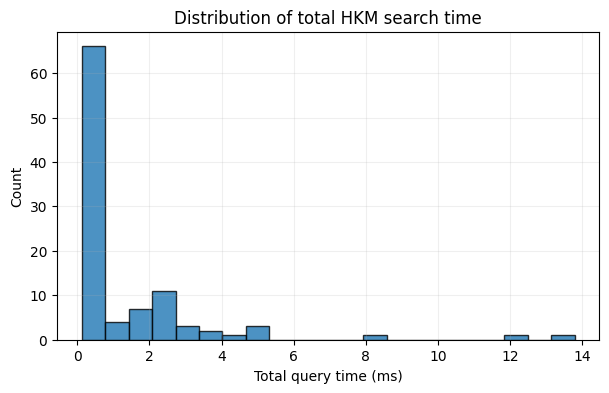

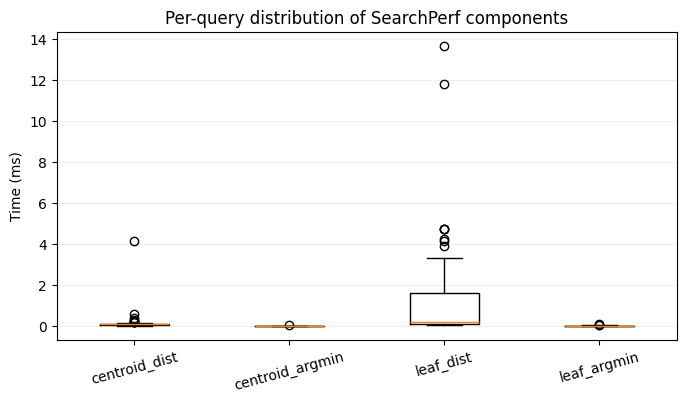

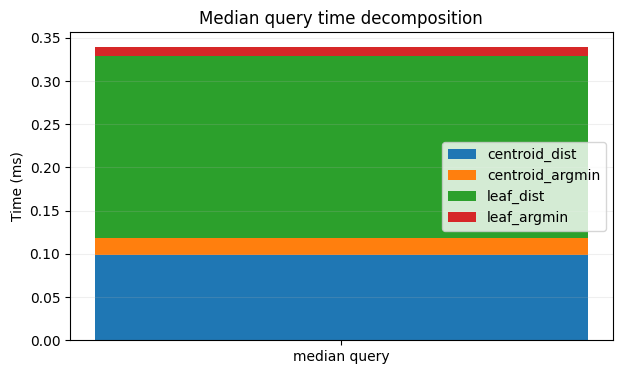

[0.09824999 0.02034999 0.21065    0.01019999]


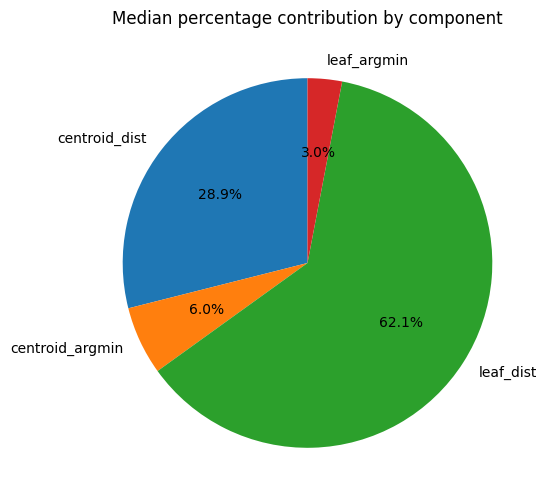

mean total:   1.3387 ms
median total: 0.3946 ms
p95 total:    4.8840 ms
centroid search iterations: 303
leaf search iterations: 100
Recall@1: 0.5800
Recall@5: 0.8700


In [187]:
# best trail k=76, L_max=14, N_min = 743
tree, stats = hkm(fvecs_base, k=4, L_max=20, N_min=300)
queries_result = []
queries_time = []
for q in fvecs_query:
    idx, perf_obj = hkm_search(tree, q)
    queries_result.append(idx)
    queries_time.append(perf_obj)

perf_viz(queries_time)
print(f"Recall@1: {recall_at_r(ivecs_groundtruth, queries_result, r=1):.4f}")
print(f"Recall@5: {recall_at_r(ivecs_groundtruth, queries_result, r=5):.4f}")

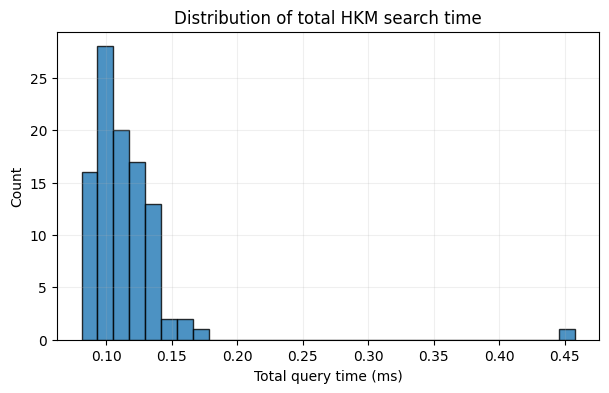

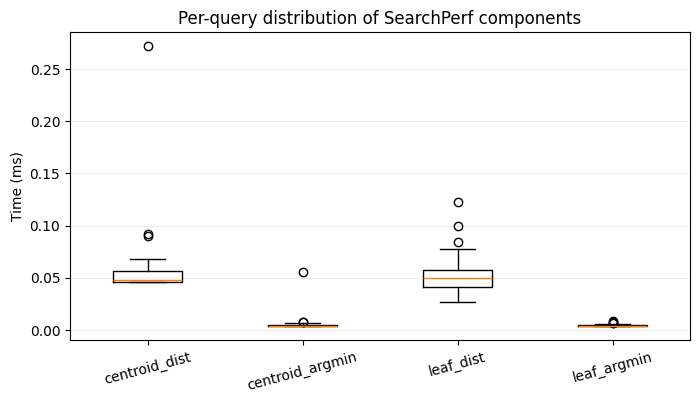

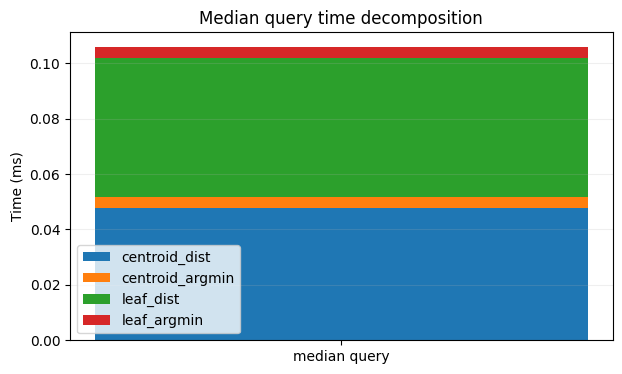

[0.0478  0.004   0.04995 0.0041 ]


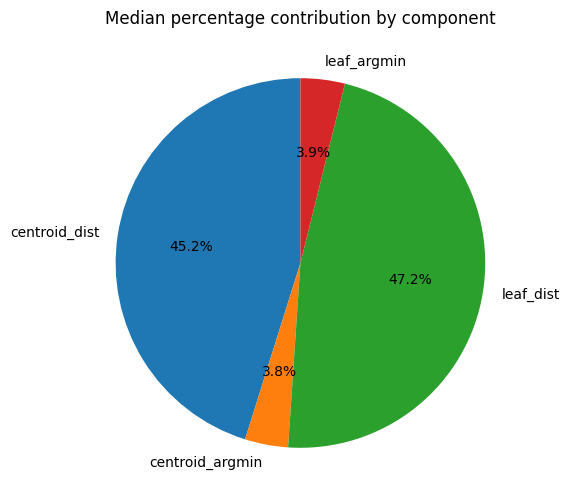

mean total:   0.1155 ms
median total: 0.1086 ms
p95 total:    0.1455 ms
centroid search iterations: 100
leaf search iterations: 100
Recall@1: 0.7100
Recall@5: 0.9400


In [ ]:
# best trail k=76, L_max=14, N_min = 743
tree, stats = hkm(fvecs_base, k=139, L_max=10, N_min=428)
queries_result = []
queries_time = []
for q in fvecs_query:
    idx, perf_obj = hkm_search(tree, q)
    queries_result.append(idx)
    queries_time.append(perf_obj)

perf_viz(queries_time)
print(f"Recall@1: {recall_at_r(ivecs_groundtruth, queries_result, r=1):.4f}")
print(f"Recall@5: {recall_at_r(ivecs_groundtruth, queries_result, r=5):.4f}")

# HNSW

In [ ]:
import faiss
import time
import numpy as np

d = fvecs_base.shape[1]

parameters = {
    "M": [3, 6, 8, 16, 32, 64],
    "efSearch": [10, 20, 50],
    "efConstruction": [100, 200, 300, 400]
}

result = []

# small grid search for HNSW

for M in parameters["M"]:
    for efSearch in parameters["efSearch"]:
        for efConstruction in parameters["efConstruction"]:
            score = 0
            print(f"Evaluating with M={M}, efSearch={efSearch}, efConstruction={efConstruction}")
            
            index = faiss.IndexHNSWFlat(d, M)  

            index.hnsw.efConstruction = efConstruction

            start = time.perf_counter()
            index.add(fvecs_base)
            build_time = (time.perf_counter() - start) * 1000  # convert to milliseconds

            index.hnsw.efSearch = efSearch

            start = time.perf_counter()

            D, I = index.search(fvecs_query, 1)
            query_time = (time.perf_counter() - start) * 1000  # convert to milliseconds
            
            score = (I[:, 0] == ivecs_groundtruth[:, 0]).mean()
            
            result.append((M, efSearch, efConstruction, query_time, score))


df = pd.DataFrame(result, columns=["M", "efSearch", "efConstruction", "estimated_time", "score"])
df.to_csv("HNSW_results.csv", index=False)

Evaluating with M=3, efSearch=10, efConstruction=100
Evaluating with M=3, efSearch=10, efConstruction=200
Evaluating with M=3, efSearch=10, efConstruction=300
Evaluating with M=3, efSearch=10, efConstruction=400
Evaluating with M=3, efSearch=20, efConstruction=100
Evaluating with M=3, efSearch=20, efConstruction=200
Evaluating with M=3, efSearch=20, efConstruction=300
Evaluating with M=3, efSearch=20, efConstruction=400
Evaluating with M=3, efSearch=50, efConstruction=100
Evaluating with M=3, efSearch=50, efConstruction=200
Evaluating with M=3, efSearch=50, efConstruction=300
Evaluating with M=3, efSearch=50, efConstruction=400
Evaluating with M=6, efSearch=10, efConstruction=100
Evaluating with M=6, efSearch=10, efConstruction=200
Evaluating with M=6, efSearch=10, efConstruction=300
Evaluating with M=6, efSearch=10, efConstruction=400
Evaluating with M=6, efSearch=20, efConstruction=100
Evaluating with M=6, efSearch=20, efConstruction=200
Evaluating with M=6, efSearch=20, efConstructi

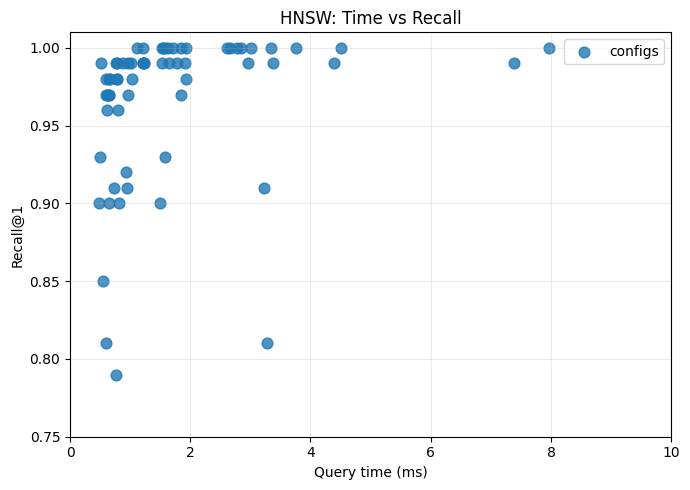

In [192]:
import matplotlib.pyplot as plt

# Optional: sort by time for a cleaner line
df_plot = df.sort_values("estimated_time").copy()

plt.figure(figsize=(7, 5))
plt.scatter(df_plot["estimated_time"], df_plot["score"], s=60, alpha=0.8, label="configs")
# plt.plot(df_plot["estimated_time"], df_plot["score"], alpha=0.4)

plt.xlabel("Query time (ms)")
plt.ylabel("Recall@1")
plt.title("HNSW: Time vs Recall")
plt.xlim(0, 10)
plt.ylim(0.75, 1.01)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# brute force search for recall baseline
def brute_force_search(D, x):
    """Brute-force nearest neighbor using np.linalg.norm.
    Returns (idx, SearchPerf) with times in milliseconds.
    """
    perf = SearchPerf()
    start = time.perf_counter()
    dists = np.linalg.norm(D - x, axis=1)
    perf.leaf_distances_time += (time.perf_counter() - start) * 1000.0

    start = time.perf_counter()
    closest_idx = np.argmin(dists)
    perf.leaf_argmin_time += (time.perf_counter() - start) * 1000.0

    return int(closest_idx), perf


def brute_force_batch(D, queries):
    """Run brute-force for each query. Returns (preds_list, perfs_list)."""
    preds = []
    perfs = []
    for q in queries:
        idx, perf = brute_force_search(D, q)
        preds.append(idx)
        perfs.append(perf)
    return preds, perfs

# Warm-up
_ = brute_force_search(fvecs_base[:1000], fvecs_query[0])

# Run over whole query set
bf_preds, bf_perfs = brute_force_batch(fvecs_base, fvecs_query)
bf_times = np.array([p.total_time() for p in bf_perfs])
print("Brute median (ms):", np.median(bf_times))
print("Brute mean (ms):", np.mean(bf_times))



Brute median (ms): 5.729650001740083
Brute mean (ms): 5.988160001143115
